In [1]:
import pandas as pd

In [2]:
li = pd.read_csv("/home/aglushkevich/Documents/Xmas_list", header=None)
li.head()

,0
0,A.arNorv-1
1,AL05-11
2,AL05-14
3,AL05-15
4,AL05-16


In [3]:
dupl = pd.read_csv("/home/aglushkevich/Documents/dupl_shit_copy.csv", sep="\t")
dupl.head()

,Unnamed: 0,total read number,avg_coverage_goleft_to_NT1final,latitude,longitude,ploidy_man_curated,nquire ploidy,proportion_het%_NT1fin,proportion_het%_MN47,Nb_S_groups_raw_DB2022,...,selection_test,Nb_S_groups_Jan2021,S_groups_Jan2021,Unnamed: 34,Unnamed: 35,Type sequencing,ENA BioSample name,het_normalized30??,Raw data,Environment_variables anaysis
0,a23003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,short-read,NaN,NaN,/biodata/dep_mercier/grp_novikova/A.Lyrata/Nov...,NaN
1,a23008,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,short-read,NaN,NaN,/biodata/dep_mercier/grp_novikova/A.Lyrata/Nov...,NaN
2,a23004-1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,short-read,NaN,NaN,/biodata/dep_mercier/grp_novikova/A.Lyrata/Nov...,NaN
3,a23005-1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,short-read,NaN,NaN,/biodata/dep_mercier/grp_novikova/A.Lyrata/Nov...,NaN
4,a23006-1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,short-read,NaN,NaN,/biodata/dep_mercier/grp_novikova/A.Lyrata/Nov...,NaN


In [4]:
dupl = dupl.rename(columns={"Unnamed: 0": "ID"})
li = li.rename(columns={0: "ID"})

In [10]:
li.merge(dupl, how="left", on="ID").to_csv("/home/aglushkevich/Documents/Xmas_vcf.tsv", sep="\t", index=False)

In [9]:
li["ID"] = li.vcf_name.str.removesuffix('_4n')

In [8]:
li = li.rename(columns={"ID": "vcf_name"})

In [4]:
gffcmp = pd.read_csv("long_braker/NT1_long_helixer.tmap", sep="\t")
gffcmp.head()

,ref_gene_id,class_code,qry_gene_id
0,AL1G10010,k,NT1_helixer_scaffold_1_005462
1,AL1G10020,j,NT1_helixer_scaffold_1_005461
2,AL1G10040,j,NT1_helixer_scaffold_1_000001
3,AL1G10050,=,NT1_helixer_scaffold_1_005460
4,AL1G10070,=,NT1_helixer_scaffold_1_005458


In [5]:
ath = pd.read_csv("long_braker/Ath_to_helixer_bracker.tsv", sep="\t")
ath.head()

,id1,id2,bitScore
0,ATCG00020,NT1_helixer_scaffold_3_002790,154.0
1,ATCG00020,NT1_helixer_scaffold_3_001805,715.0
2,ATCG00120,NT1_helixer_scaffold_3_001788,58.5
3,ATCG00120,NT1_helixer_scaffold_3_001803,945.0
4,ATCG00120,NT1_helixer_scaffold_2_000840,91.7


In [6]:
al = pd.read_csv("long_braker/MN47_to_helixer_bracker.tsv", sep="\t")
al.head()

,id1,id2,bitScore
0,NT1_helixer_scaffold_1_005462,AL1G10010,876.0
1,NT1_helixer_scaffold_1_005462,AL1G10020,566.0
2,NT1_helixer_scaffold_1_005461,AL1G10010,447.0
3,NT1_helixer_scaffold_1_005461,AL1G10020,1012.0
4,NT1_helixer_scaffold_1_005456,AL1G10110,1119.0


In [26]:
ids_ath = ath.groupby(by='id2')['bitScore'].idxmax()

In [29]:
ath[ath.id2 == "NT1_helixer_scaffold_8_003586"]

,id1,id2,bitScore
30818,AT5G47640,NT1_helixer_scaffold_8_003586,155.0
30822,AT5G47670,NT1_helixer_scaffold_8_003586,464.0


In [30]:
ath_max = ath.loc[ids_ath]

In [31]:
ids_al = al.groupby(by='id1')['bitScore'].idxmax()
al_max = al.loc[ids_al]

In [33]:
al_max = al_max.rename(columns={'id1': "helixer", "id2": "mn47", "bitScore": "bitScore_mn47"})

In [34]:
ath_max = ath_max.rename(columns={'id1': "Ath", "id2": "helixer", "bitScore": "bitScore_ath"})

In [53]:
ly_to_ath = pd.read_csv("long_braker/Ath_to_aly_cut.txt", sep="\t", header=None)
ly_to_ath.head()

,0,1
0,AL1006U10010,AT5G34885
1,AL1008U10010,AT5G42830
2,AL100U10010,AT2G39210
3,AL100U10020,AT2G39200
4,AL1010U10010,AT5G58730


In [54]:
ly_to_ath = ly_to_ath.rename(columns={0: "mn47_phytozome", 1: "Ath"})

In [37]:
gffcmp = gffcmp.rename(columns={"qry_gene_id": "helixer", "ref_gene_id": "gffcmp"})

In [38]:
gffcmp.shape

(25885, 3)

In [39]:
al_max.shape

(25407, 3)

In [40]:
ath_max.shape

(24106, 3)

In [68]:
combo = gffcmp.merge(al_max, on='helixer', how="outer")

In [69]:
combo = combo.merge(ath_max, on='helixer', how="outer")

In [64]:
combo.merge(ly_to_ath, on='Ath', how="left")

,gffcmp,class_code,helixer,mn47,bitScore_mn47,Ath,bitScore_ath,mn47_phytozome
0,AL1G10010,k,NT1_helixer_scaffold_1_005462,AL1G10010,876.0,AT1G02205,881.0,AL1G10010
1,AL1G10020,j,NT1_helixer_scaffold_1_005461,AL1G10020,1012.0,AT1G02190,1078.0,AL1G10020
2,AL1G10020,j,NT1_helixer_scaffold_1_005461,AL1G10020,1012.0,AT1G02190,1078.0,AL1G56730
3,AL1G10020,j,NT1_helixer_scaffold_1_005461,AL1G10020,1012.0,AT1G02190,1078.0,AL1G56780
4,AL1G10020,j,NT1_helixer_scaffold_1_005461,AL1G10020,1012.0,AT1G02190,1078.0,AL2G22020
...,...,...,...,...,...,...,...,...
8519587,NaN,NaN,NT1_helixer_scaffold_8_003442,NaN,NaN,AT5G45570,59.7,AL6G43460
8519588,NaN,NaN,NT1_helixer_scaffold_8_003442,NaN,NaN,AT5G45570,59.7,AL7G43910
8519589,NaN,NaN,NT1_helixer_scaffold_8_003442,NaN,NaN,AT5G45570,59.7,AL7G44740
8519590,NaN,NaN,NT1_helixer_scaffold_8_003442,NaN,NaN,AT5G45570,59.7,AL8G21960


In [71]:
combo.to_csv("long_braker/functional_overlap2.tsv", sep="\t", index=False)

In [61]:
ly_to_ath

,mn47_phytozome,Ath
0,AL1006U10010,AT5G34885
1,AL1008U10010,AT5G42830
2,AL100U10010,AT2G39210
3,AL100U10020,AT2G39200
4,AL1010U10010,AT5G58730
...,...,...
33127,AL9U12200,AT4G12690
33128,AL9U12210,AT4G12700
33129,AL9U12220,AT4G12710
33130,AL9U12230,AT4G12720


In [67]:
ath_max = ath_max.merge(ly_to_ath, on='Ath', how="left")

In [147]:
clear = combo[(combo.gffcmp == combo.mn47_phytozome) & (combo.gffcmp == combo.mn47)]

In [151]:
clear.gffcmp.value_counts()

AL6G35700    3
AL1G57560    3
AL5G45250    3
AL2G31730    3
AL2G10610    2
            ..
AL3G30010    1
AL3G30000    1
AL3G29990    1
AL3G29980    1
AL8G45710    1
Name: gffcmp, Length: 20034, dtype: int64

In [149]:
combo_rest = combo[combo.helixer.isin(clear.helixer) == False]

In [155]:
major = combo_rest[(combo_rest.gffcmp == combo_rest.mn47) | (combo_rest.gffcmp == combo_rest.mn47_phytozome) | (combo_rest.mn47 == combo_rest.mn47_phytozome)]

In [156]:
combo_rest = combo_rest[combo_rest.helixer.isin(major.helixer) == False]

In [83]:
combo_rest.helixer.value_counts()

NT1_helixer_scaffold_8_003442    28
NT1_helixer_scaffold_8_000153    28
NT1_helixer_scaffold_1_001659    11
NT1_helixer_scaffold_3_002985    10
NT1_helixer_scaffold_2_000074     8
                                 ..
NT1_helixer_scaffold_4_001513     1
NT1_helixer_scaffold_4_002222     1
NT1_helixer_scaffold_4_002216     1
NT1_helixer_scaffold_4_002211     1
NT1_helixer_scaffold_6_002015     1
Name: helixer, Length: 3971, dtype: int64

In [88]:
combo_rest.class_code.value_counts()

j    789
=    584
o    338
k    208
x    200
p    195
n    178
m    155
c     83
i     41
e     33
y      3
Name: class_code, dtype: int64

In [158]:
gff_only = combo_rest[combo_rest.class_code.isin(["m", "=", "k", "c"]) & combo_rest.mn47.isna() & combo_rest.Ath.isna() ]

In [159]:
ly_only = combo_rest[combo_rest.gffcmp.isna() & (combo_rest.mn47.isna() == False) & combo_rest.Ath.isna()]

In [99]:
gff_only

,gffcmp,class_code,helixer,mn47,bitScore_mn47,Ath,bitScore_ath,mn47_phytozome
211,AL1G11860,m,NT1_helixer_scaffold_1_000079,NaN,NaN,NaN,NaN,NaN
351,AL1G13160,m,NT1_helixer_scaffold_1_005293,NaN,NaN,NaN,NaN,NaN
364,AL1G13230,m,NT1_helixer_scaffold_1_000146,NaN,NaN,NaN,NaN,NaN
396,AL5G28770,k,NT1_helixer_scaffold_1_000159,NaN,NaN,NaN,NaN,NaN
506,AL325U10020,=,NT1_helixer_scaffold_1_005225,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
33887,AL2G20560,c,NT1_helixer_scaffold_85_000016,NaN,NaN,NaN,NaN,NaN
33889,AL2G21380,k,NT1_helixer_scaffold_86_000006,NaN,NaN,NaN,NaN,NaN
33890,AL3G43780,=,NT1_helixer_scaffold_87_000013,NaN,NaN,NaN,NaN,NaN
33894,AL2G21100,=,NT1_helixer_scaffold_9_000012,NaN,NaN,NaN,NaN,NaN


In [160]:
ath_only = combo_rest[combo_rest.gffcmp.isna() & (combo_rest.mn47_phytozome.isna() == False) & combo_rest.mn47.isna()]

In [252]:
ath_only_g.to_csv("Functional_athonly.tsv", sep="\t")

In [136]:
ath_only = combo_rest[combo_rest.gffcmp.isna() & (combo_rest.mn47_phytozome.isna() == False) & combo_rest.mn47.isna() & combo_rest.helixer.isin(mask.index)]



In [116]:
combo_rest.helixer.isin(combo_rest.helixer[combo_rest.helixer.value_counts()==1])

IndexingError: Unalignable boolean Series provided as indexer (index of the boolean Series and of the indexed object do not match).

In [119]:
(combo_rest.helixer.value_counts()==1).index

Index(['NT1_helixer_scaffold_8_003442', 'NT1_helixer_scaffold_8_000153',
       'NT1_helixer_scaffold_1_001659', 'NT1_helixer_scaffold_3_002985',
       'NT1_helixer_scaffold_2_000074', 'NT1_helixer_scaffold_2_003430',
       'NT1_helixer_scaffold_2_003420', 'NT1_helixer_scaffold_7_003928',
       'NT1_helixer_scaffold_3_003429', 'NT1_helixer_scaffold_3_003431',
       ...
       'NT1_helixer_scaffold_4_001453', 'NT1_helixer_scaffold_4_001460',
       'NT1_helixer_scaffold_4_002278', 'NT1_helixer_scaffold_4_002271',
       'NT1_helixer_scaffold_4_001497', 'NT1_helixer_scaffold_4_001513',
       'NT1_helixer_scaffold_4_002222', 'NT1_helixer_scaffold_4_002216',
       'NT1_helixer_scaffold_4_002211', 'NT1_helixer_scaffold_6_002015'],
      dtype='object', length=3971)

In [122]:
combo_rest.helixer[combo_rest.helixer.isin((combo_rest.helixer.value_counts()==1).index)]

36       NT1_helixer_scaffold_1_005447
58       NT1_helixer_scaffold_1_000024
110      NT1_helixer_scaffold_1_000041
188      NT1_helixer_scaffold_1_000070
211      NT1_helixer_scaffold_1_000079
                     ...              
37309    NT1_helixer_scaffold_8_003442
37310    NT1_helixer_scaffold_8_003442
37311    NT1_helixer_scaffold_8_003442
37312    NT1_helixer_scaffold_8_003442
37313    NT1_helixer_scaffold_8_003442
Name: helixer, Length: 4282, dtype: object

In [129]:
((combo_rest.helixer.value_counts()==1) == True).index

Index(['NT1_helixer_scaffold_8_003442', 'NT1_helixer_scaffold_8_000153',
       'NT1_helixer_scaffold_1_001659', 'NT1_helixer_scaffold_3_002985',
       'NT1_helixer_scaffold_2_000074', 'NT1_helixer_scaffold_2_003430',
       'NT1_helixer_scaffold_2_003420', 'NT1_helixer_scaffold_7_003928',
       'NT1_helixer_scaffold_3_003429', 'NT1_helixer_scaffold_3_003431',
       ...
       'NT1_helixer_scaffold_4_001453', 'NT1_helixer_scaffold_4_001460',
       'NT1_helixer_scaffold_4_002278', 'NT1_helixer_scaffold_4_002271',
       'NT1_helixer_scaffold_4_001497', 'NT1_helixer_scaffold_4_001513',
       'NT1_helixer_scaffold_4_002222', 'NT1_helixer_scaffold_4_002216',
       'NT1_helixer_scaffold_4_002211', 'NT1_helixer_scaffold_6_002015'],
      dtype='object', length=3971)

In [126]:
combo_rest.helixer.isin((combo_rest.helixer.value_counts()==1).index)

36       True
58       True
110      True
188      True
211      True
         ... 
37309    True
37310    True
37311    True
37312    True
37313    True
Name: helixer, Length: 4282, dtype: bool

In [130]:
mask = combo_rest.helixer.value_counts() == 1

In [133]:
mask = mask[mask ==True]

In [139]:
combo[combo.gffcmp == "AL1G15680"]

,gffcmp,class_code,helixer,mn47,bitScore_mn47,Ath,bitScore_ath,mn47_phytozome
648,AL1G15680,j,NT1_helixer_scaffold_1_000251,NaN,NaN,AT1G05785,255.0,NaN


In [140]:
combo[combo.mn47 == "AL1G15680"]

,gffcmp,class_code,helixer,mn47,bitScore_mn47,Ath,bitScore_ath,mn47_phytozome
33908,NaN,NaN,NT1_helixer_scaffold_1_000250,AL1G15680,159.0,AT1G05780,155.0,AL1G15680
33909,NaN,NaN,NT1_helixer_scaffold_1_000250,AL1G15680,159.0,AT1G05780,155.0,AL1G15680
33910,NaN,NaN,NT1_helixer_scaffold_1_000250,AL1G15680,159.0,AT1G05780,155.0,AL1G15680


In [152]:
combo[combo.mn47_phytozome == "AL6G35700"]

,gffcmp,class_code,helixer,mn47,bitScore_mn47,Ath,bitScore_ath,mn47_phytozome
23736,AL6G35690,m,NT1_helixer_scaffold_6_003072,AL6G35710,419.0,AT5G24280,417.0,AL6G35700
23739,AL6G35700,j,NT1_helixer_scaffold_6_003071,AL6G35700,176.0,AT5G24280,106.0,AL6G35700
23742,AL6G35700,c,NT1_helixer_scaffold_6_003070,AL6G35700,275.0,AT5G24280,183.0,AL6G35700
23745,AL6G35700,j,NT1_helixer_scaffold_6_003069,AL6G35700,207.0,AT5G24280,81.3,AL6G35700
23748,AL6G35700,j,NT1_helixer_scaffold_6_003068,AL6G35710,403.0,AT5G24280,382.0,AL6G35700


In [145]:
combo = combo.drop_duplicates()

In [146]:
combo

,gffcmp,class_code,helixer,mn47,bitScore_mn47,Ath,bitScore_ath,mn47_phytozome
0,AL1G10010,k,NT1_helixer_scaffold_1_005462,AL1G10010,876.0,AT1G02205,881.0,AL1G10010
1,AL1G10020,j,NT1_helixer_scaffold_1_005461,AL1G10020,1012.0,AT1G02190,1078.0,AL1G10020
2,AL1G10020,j,NT1_helixer_scaffold_1_005461,AL1G10020,1012.0,AT1G02190,1078.0,AL1G56730
3,AL1G10020,j,NT1_helixer_scaffold_1_005461,AL1G10020,1012.0,AT1G02190,1078.0,AL1G56780
4,AL1G10020,j,NT1_helixer_scaffold_1_005461,AL1G10020,1012.0,AT1G02190,1078.0,AL2G22020
...,...,...,...,...,...,...,...,...
37308,NaN,NaN,NT1_helixer_scaffold_8_003442,NaN,NaN,AT5G45570,59.7,AL6G43460
37310,NaN,NaN,NT1_helixer_scaffold_8_003442,NaN,NaN,AT5G45570,59.7,AL7G43910
37311,NaN,NaN,NT1_helixer_scaffold_8_003442,NaN,NaN,AT5G45570,59.7,AL7G44740
37312,NaN,NaN,NT1_helixer_scaffold_8_003442,NaN,NaN,AT5G45570,59.7,AL8G21960


In [150]:
combo_rest 

,gffcmp,class_code,helixer,mn47,bitScore_mn47,Ath,bitScore_ath,mn47_phytozome
11,AL1G10102,j,NT1_helixer_scaffold_1_000003,AL1G10102,456.0,NaN,NaN,NaN
20,AL1G10160,=,NT1_helixer_scaffold_1_005452,AL1G10160,659.0,NaN,NaN,NaN
30,AL1G10260,n,NT1_helixer_scaffold_1_000010,AL1G10260,253.0,AT1G02030,320.0,NaN
32,AL1G10270,j,NT1_helixer_scaffold_1_005448,AL1G10290,685.0,AT1G02010,566.0,AL1G10270
33,AL1G10270,j,NT1_helixer_scaffold_1_005448,AL1G10290,685.0,AT1G02010,566.0,AL1G10310
...,...,...,...,...,...,...,...,...
37308,NaN,NaN,NT1_helixer_scaffold_8_003442,NaN,NaN,AT5G45570,59.7,AL6G43460
37310,NaN,NaN,NT1_helixer_scaffold_8_003442,NaN,NaN,AT5G45570,59.7,AL7G43910
37311,NaN,NaN,NT1_helixer_scaffold_8_003442,NaN,NaN,AT5G45570,59.7,AL7G44740
37312,NaN,NaN,NT1_helixer_scaffold_8_003442,NaN,NaN,AT5G45570,59.7,AL8G21960


In [167]:
clear.groupby('helixer').sum(numeric_only = False)

,gffcmp,class_code,mn47,bitScore_mn47,Ath,bitScore_ath,mn47_phytozome
helixer,,,,,,,
NT1_helixer_scaffold_1_000001,AL1G10040,j,AL1G10040,454.0,AT1G02180,416.0,AL1G10040
NT1_helixer_scaffold_1_000002,AL1G10090,=,AL1G10090,301.0,AT1G02140,299.0,AL1G10090
NT1_helixer_scaffold_1_000004,AL1G10104,=,AL1G10104,405.0,AT1G02130,403.0,AL1G10104
NT1_helixer_scaffold_1_000005,AL1G10140,j,AL1G10140,496.0,AT1G02090,475.0,AL1G10140
NT1_helixer_scaffold_1_000006,AL1G10200,j,AL1G10200,4553.0,AT1G02080,4331.0,AL1G10200
...,...,...,...,...,...,...,...
NT1_helixer_scaffold_8_003586,AL8G10280,=,AL8G10280,471.0,AT5G47670,464.0,AL8G10280
NT1_helixer_scaffold_8_003587,AL8G10260,j,AL8G10260,2982.0,AT5G47690,2839.0,AL8G10260
NT1_helixer_scaffold_8_003588,AL8G10240,j,AL8G10240,327.0,AT5G47710,328.0,AL8G10240


In [169]:
major

,gffcmp,class_code,helixer,mn47,bitScore_mn47,Ath,bitScore_ath,mn47_phytozome
11,AL1G10102,j,NT1_helixer_scaffold_1_000003,AL1G10102,456.0,NaN,NaN,NaN
20,AL1G10160,=,NT1_helixer_scaffold_1_005452,AL1G10160,659.0,NaN,NaN,NaN
30,AL1G10260,n,NT1_helixer_scaffold_1_000010,AL1G10260,253.0,AT1G02030,320.0,NaN
32,AL1G10270,j,NT1_helixer_scaffold_1_005448,AL1G10290,685.0,AT1G02010,566.0,AL1G10270
51,AL1G10400,o,NT1_helixer_scaffold_1_000018,AL1G10400,172.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
36760,NaN,NaN,NT1_helixer_scaffold_8_003387,AL8G14480,463.0,AT5G44980,536.0,AL8G14480
36764,NaN,NaN,NT1_helixer_scaffold_8_003491,AL8G12140,73.9,AT5G46300,58.2,AL8G12140
36766,NaN,NaN,NT1_helixer_scaffold_8_003540,AL8G11420,173.0,AT5G46871,153.0,AL8G11420
36767,NaN,NaN,NT1_helixer_scaffold_8_003558,AL8G10770,505.0,AT5G47250,872.0,AL8G10770


In [170]:
major.groupby('helixer').sum(numeric_only = False)

,gffcmp,class_code,mn47,bitScore_mn47,Ath,bitScore_ath,mn47_phytozome
helixer,,,,,,,
NT1_helixer_scaffold_1_000003,AL1G10102,j,AL1G10102,456.0,0,0.0,0
NT1_helixer_scaffold_1_000010,AL1G10260,n,AL1G10260,253.0,AT1G02030,320.0,0
NT1_helixer_scaffold_1_000018,AL1G10400,o,AL1G10400,172.0,0,0.0,0
NT1_helixer_scaffold_1_000055,0,0,AL1G11330,176.0,AT1G01170,171.0,AL1G11330
NT1_helixer_scaffold_1_000058,AL1G11390,o,AL1G11390,252.0,AT1G01130,126.0,0
...,...,...,...,...,...,...,...
NT1_helixer_scaffold_8_003550,AL8G11000AL8G11000,kk,AL8G11110AL8G11110,1106.0,AT5G47090AT5G47090,934.0,AL8G11000AL8G11110
NT1_helixer_scaffold_8_003558,0,0,AL8G10770,505.0,AT5G47250,872.0,AL8G10770
NT1_helixer_scaffold_8_003561,0,0,AL8G10790,434.0,AT5G47240,427.0,AL8G10790


In [174]:
major.groupby('helixer').apply(','.join)

helixer
NT1_helixer_scaffold_1_000003    gffcmp,class_code,helixer,mn47,bitScore_mn47,A...
NT1_helixer_scaffold_1_000010    gffcmp,class_code,helixer,mn47,bitScore_mn47,A...
NT1_helixer_scaffold_1_000018    gffcmp,class_code,helixer,mn47,bitScore_mn47,A...
NT1_helixer_scaffold_1_000055    gffcmp,class_code,helixer,mn47,bitScore_mn47,A...
NT1_helixer_scaffold_1_000058    gffcmp,class_code,helixer,mn47,bitScore_mn47,A...
                                                       ...                        
NT1_helixer_scaffold_8_003550    gffcmp,class_code,helixer,mn47,bitScore_mn47,A...
NT1_helixer_scaffold_8_003558    gffcmp,class_code,helixer,mn47,bitScore_mn47,A...
NT1_helixer_scaffold_8_003561    gffcmp,class_code,helixer,mn47,bitScore_mn47,A...
NT1_helixer_scaffold_8_003570    gffcmp,class_code,helixer,mn47,bitScore_mn47,A...
NT1_helixer_scaffold_8_003591    gffcmp,class_code,helixer,mn47,bitScore_mn47,A...
Length: 4270, dtype: object

In [177]:
major[(major.gffcmp == major.mn47)]

,gffcmp,class_code,helixer,mn47,bitScore_mn47,Ath,bitScore_ath,mn47_phytozome
11,AL1G10102,j,NT1_helixer_scaffold_1_000003,AL1G10102,456.0,NaN,NaN,NaN
20,AL1G10160,=,NT1_helixer_scaffold_1_005452,AL1G10160,659.0,NaN,NaN,NaN
30,AL1G10260,n,NT1_helixer_scaffold_1_000010,AL1G10260,253.0,AT1G02030,320.0,NaN
51,AL1G10400,o,NT1_helixer_scaffold_1_000018,AL1G10400,172.0,NaN,NaN,NaN
72,AL1G10640,k,NT1_helixer_scaffold_1_005430,AL1G10640,272.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
33774,AL8G44850,j,NT1_helixer_scaffold_8_001916,AL8G44850,630.0,AT5G66610,285.0,AL8G44890
33779,AL8G44880,=,NT1_helixer_scaffold_8_001913,AL8G44880,805.0,AT5G66630,536.0,NaN
33786,AL8G44900,=,NT1_helixer_scaffold_8_001836,AL8G44900,200.0,NaN,NaN,NaN
33814,AL8G45080,n,NT1_helixer_scaffold_8_001847,AL8G45080,856.0,NaN,NaN,NaN


In [181]:
majorg = major[(major.gffcmp == major.mn47)].groupby('helixer').max()

In [187]:
major[(major.gffcmp == major.mn47_phytozome)].groupby('helixer').max()

,gffcmp,class_code,mn47,bitScore_mn47,Ath,bitScore_ath,mn47_phytozome
helixer,,,,,,,
NT1_helixer_scaffold_1_000137,AL1G13550,n,AL1G12990,475.0,AT1G03490,217.0,AL1G13550
NT1_helixer_scaffold_1_000145,AL1G13200,m,AL1G13220,365.0,AT1G03710,157.0,AL1G13200
NT1_helixer_scaffold_1_000248,AL1G15650,j,AL1G15640,167.0,AT1G05740,165.0,AL1G15650
NT1_helixer_scaffold_1_000322,AL1G17100,j,AL1G16930,174.0,AT1G06950,253.0,AL1G17100
NT1_helixer_scaffold_1_000348,AL1G17620,=,AL1G17650,691.0,AT1G07470,687.0,AL1G17620
...,...,...,...,...,...,...,...
NT1_helixer_scaffold_8_003399,AL8G14440,k,AL8G14570,357.0,AT5G45000,650.0,AL8G14440
NT1_helixer_scaffold_8_003420,AL8G13710,j,AL8G13580,1359.0,AT5G45050,1501.0,AL8G13710
NT1_helixer_scaffold_8_003445,AL1G45720,m,NaN,NaN,AT5G45400,1299.0,AL1G45720


In [189]:
majorg2 = major[(major.gffcmp == major.mn47_phytozome)]

In [192]:
majorg3 = major[(major.mn47 == major.mn47_phytozome)]

In [191]:
major[(major.mn47 == major.mn47_phytozome)].groupby('helixer').max()

,gffcmp,class_code,mn47,bitScore_mn47,Ath,bitScore_ath,mn47_phytozome
helixer,,,,,,,
NT1_helixer_scaffold_1_000055,NaN,NaN,AL1G11330,176.0,AT1G01170,171.0,AL1G11330
NT1_helixer_scaffold_1_000059,NaN,NaN,AL1G11370,83.2,AT1G01140,83.2,AL1G11370
NT1_helixer_scaffold_1_000088,NaN,NaN,AL1G11990,228.0,AT1G02650,218.0,AL1G11990
NT1_helixer_scaffold_1_000104,NaN,NaN,AL1G12260,73.6,AT1G02850,66.6,AL1G12260
NT1_helixer_scaffold_1_000134,NaN,NaN,AL1G12930,97.1,AT1G03430,94.7,AL1G12930
...,...,...,...,...,...,...,...
NT1_helixer_scaffold_8_003540,NaN,NaN,AL8G11420,173.0,AT5G46871,153.0,AL8G11420
NT1_helixer_scaffold_8_003550,AL8G11000,k,AL8G11110,553.0,AT5G47090,467.0,AL8G11110
NT1_helixer_scaffold_8_003558,NaN,NaN,AL8G10770,505.0,AT5G47250,872.0,AL8G10770


In [198]:
gff_only

,gffcmp,class_code,helixer,mn47,bitScore_mn47,Ath,bitScore_ath,mn47_phytozome
211,AL1G11860,m,NT1_helixer_scaffold_1_000079,NaN,NaN,NaN,NaN,NaN
351,AL1G13160,m,NT1_helixer_scaffold_1_005293,NaN,NaN,NaN,NaN,NaN
364,AL1G13230,m,NT1_helixer_scaffold_1_000146,NaN,NaN,NaN,NaN,NaN
396,AL5G28770,k,NT1_helixer_scaffold_1_000159,NaN,NaN,NaN,NaN,NaN
506,AL325U10020,=,NT1_helixer_scaffold_1_005225,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
33887,AL2G20560,c,NT1_helixer_scaffold_85_000016,NaN,NaN,NaN,NaN,NaN
33889,AL2G21380,k,NT1_helixer_scaffold_86_000006,NaN,NaN,NaN,NaN,NaN
33890,AL3G43780,=,NT1_helixer_scaffold_87_000013,NaN,NaN,NaN,NaN,NaN
33894,AL2G21100,=,NT1_helixer_scaffold_9_000012,NaN,NaN,NaN,NaN,NaN


In [211]:
majorg = majorg.merge(ly_to_ath, on="gffcmp", how='left')

In [241]:
ly_to_ath = ly_to_ath.rename(columns={"gffcmp": "mn47"})

In [209]:
majorg = majorg.reset_index()

In [225]:
majorg_try = majorg.groupby('helixer')[["gffcmp", "Ath_y"]].agg({"gffcmp": max, "Ath_y": sum})

In [215]:
data = {
    'Category': ['A', 'A', 'B', 'B', 'C', 'C'],
    'Item1': ['apple', 'banana', 'carrot', 'date', 'eggplant', 'fig'],
    'Item2': ['avocado', 'blueberry', 'cherry', 'date', 'fig', 'grape']
}

df = pd.DataFrame(data)

# Group by 'Category' and join values in both 'Item1' and 'Item2'
result = df.groupby('Category').agg({
    'Item1': ', '.join,
    'Item2': ', '.join
}).reset_index()

In [216]:
result

,Category,Item1,Item2
0,A,"apple, banana","avocado, blueberry"
1,B,"carrot, date","cherry, date"
2,C,"eggplant, fig","fig, grape"


In [223]:
majorg.Ath_y.value_counts()

AT1G70770    9
AT5G41690    9
AT4G36840    7
AT3G27900    7
AT4G21380    7
            ..
AT1G50790    1
AT5G18880    1
AT5G22030    1
AT1G06900    1
AT3G45630    1
Name: Ath_y, Length: 1580, dtype: int64

In [229]:
gff_only = gff_only.merge(ly_to_ath, on="gffcmp", how='left')

In [230]:
gff_only

,gffcmp,class_code,helixer,mn47,bitScore_mn47,Ath_x,bitScore_ath,mn47_phytozome,Ath_y
0,AL1G11860,m,NT1_helixer_scaffold_1_000079,NaN,NaN,NaN,NaN,NaN,AT1G02520
1,AL1G13160,m,NT1_helixer_scaffold_1_005293,NaN,NaN,NaN,NaN,NaN,AT1G03670
2,AL1G13230,m,NT1_helixer_scaffold_1_000146,NaN,NaN,NaN,NaN,NaN,AT1G03710
3,AL5G28770,k,NT1_helixer_scaffold_1_000159,NaN,NaN,NaN,NaN,NaN,NaN
4,AL325U10020,=,NT1_helixer_scaffold_1_005225,NaN,NaN,NaN,NaN,NaN,AT1G30600
...,...,...,...,...,...,...,...,...,...
904,AL2G20560,c,NT1_helixer_scaffold_85_000016,NaN,NaN,NaN,NaN,NaN,ATCG00770
905,AL2G21380,k,NT1_helixer_scaffold_86_000006,NaN,NaN,NaN,NaN,NaN,ATCG00350
906,AL3G43780,=,NT1_helixer_scaffold_87_000013,NaN,NaN,NaN,NaN,NaN,ATCG00680
907,AL2G21100,=,NT1_helixer_scaffold_9_000012,NaN,NaN,NaN,NaN,NaN,ATCG00440


In [245]:
ly_only_g = ly_only.groupby('helixer')[["mn47", "Ath_y2"]].agg({"mn47": max, "Ath_y2": ','.join})

In [244]:
ly_only["Ath_y2"] = ly_only.Ath_y.apply(str)

In [237]:
gff_only

,gffcmp,class_code,helixer,mn47,bitScore_mn47,Ath_x,bitScore_ath,mn47_phytozome,Ath_y,Ath_y2
0,AL1G11860,m,NT1_helixer_scaffold_1_000079,NaN,NaN,NaN,NaN,NaN,AT1G02520,AT1G02520
1,AL1G13160,m,NT1_helixer_scaffold_1_005293,NaN,NaN,NaN,NaN,NaN,AT1G03670,AT1G03670
2,AL1G13230,m,NT1_helixer_scaffold_1_000146,NaN,NaN,NaN,NaN,NaN,AT1G03710,AT1G03710
3,AL5G28770,k,NT1_helixer_scaffold_1_000159,NaN,NaN,NaN,NaN,NaN,NaN,nan
4,AL325U10020,=,NT1_helixer_scaffold_1_005225,NaN,NaN,NaN,NaN,NaN,AT1G30600,AT1G30600
...,...,...,...,...,...,...,...,...,...,...
904,AL2G20560,c,NT1_helixer_scaffold_85_000016,NaN,NaN,NaN,NaN,NaN,ATCG00770,ATCG00770
905,AL2G21380,k,NT1_helixer_scaffold_86_000006,NaN,NaN,NaN,NaN,NaN,ATCG00350,ATCG00350
906,AL3G43780,=,NT1_helixer_scaffold_87_000013,NaN,NaN,NaN,NaN,NaN,ATCG00680,ATCG00680
907,AL2G21100,=,NT1_helixer_scaffold_9_000012,NaN,NaN,NaN,NaN,NaN,ATCG00440,ATCG00440


In [239]:
gff_only_g 

,gffcmp,Ath_y2
helixer,,
NT1_helixer_scaffold_117_000017,AL2G21550,ATCG00520
NT1_helixer_scaffold_118_000016,AL2G20590,ATCG00730
NT1_helixer_scaffold_137_000013,AL2G21710,ATCG00750
NT1_helixer_scaffold_188_000015,AL2G21690,ATCG00730
NT1_helixer_scaffold_19_000027,AL2G20666,ATCG00520
...,...,...
NT1_helixer_scaffold_8_003569,AL8G10700,AT5G47350
NT1_helixer_scaffold_8_003571,AL8G10690,AT5G47350
NT1_helixer_scaffold_8_003578,AL8G10500,"AT5G47480,AT5G47480"


In [243]:
ly_only = ly_only.merge(ly_to_ath, on="mn47", how='left')

In [246]:
ly_only_g

,mn47,Ath_y2
helixer,,
NT1_helixer_scaffold_1_000091,AL1G11960,AT3G62850
NT1_helixer_scaffold_1_000354,AL1G17790,AT1G07610
NT1_helixer_scaffold_1_000406,AL1G19110,AT2G22340
NT1_helixer_scaffold_1_000563,AL1G22210,nan
NT1_helixer_scaffold_1_001072,AL1G32050,AT3G19515
...,...,...
NT1_helixer_scaffold_8_003261,AL8G16710,AT5G49840
NT1_helixer_scaffold_8_003263,AL8G16460,AT5G43745
NT1_helixer_scaffold_8_003467,AL8G12790,nan


In [251]:
ath_only_g = ath_only.groupby('helixer')[["mn47_phytozome", "Ath"]].agg({"mn47_phytozome": ','.join, "Ath": max})

In [253]:
agat = pd.read_csv("annot_for_agat.tsv", sep="\t")
agat

,ID,lyrata,thaliana
0,NT1_helixer_scaffold_1_005462,AL1G10010,AT1G02205
1,NT1_helixer_scaffold_1_005461,AL1G10020,AT1G02190
2,NT1_helixer_scaffold_1_000001,AL1G10040,AT1G02180
3,NT1_helixer_scaffold_1_005460,AL1G10050,AT1G02170
4,NT1_helixer_scaffold_1_005458,AL1G10070,AT1G02150
...,...,...,...
26392,NT1_helixer_scaffold_8_002178,"AL1G64110,AL1G64160,AL8G39240,AL8G39250",AT5G62410
26393,NT1_helixer_scaffold_8_002692,"AL8G29290,AL8G29320",AT5G54148
26394,NT1_helixer_scaffold_8_002721,"AL8G28460,AL8G28750",AT5G53620
26395,NT1_helixer_scaffold_8_003060,AL3G16620,AT5G48670


In [255]:
agat = agat.groupby("ID").first()

In [256]:
agat.to_csv("Agat_annot_dropdup.tsv", sep="\t")

In [2]:
li = pd.read_csv("../Eur_lyrata/Admixture2_k8_rn.tsv", header=None, sep=" ")
li.head()

,0,1,2,3,4,5,6,7,8
0,lyrNC1_01,0.000010,0.000010,0.00001,0.999930,0.000010,0.00001,0.00001,0.00001
1,lyrNC1_13,0.000010,0.000010,0.00001,0.999930,0.000010,0.00001,0.00001,0.00001
2,lyrTN1_01,0.000011,0.000010,0.00001,0.999929,0.000010,0.00001,0.00001,0.00001
3,lyrTN1_08,0.000012,0.000011,0.00001,0.999924,0.000013,0.00001,0.00001,0.00001
4,lyrNC2_03,0.000010,0.000019,0.00001,0.999921,0.000010,0.00001,0.00001,0.00001


In [26]:
li[li.iloc[:,9] >= 0.8].iloc[:,0]

102     GYE8_4n
103     GYE7_4n
104     GYE6_4n
105     GYE5_4n
106     GYE4_4n
         ...   
294     SCT2_4n
295     SCT1_4n
296     SCT8_4n
297     SCT9_4n
298    SCT10_4n
Name: 0, Length: 171, dtype: object

In [48]:
li[li.iloc[:,9] >= 0.8].iloc[:,0].to_csv("../Eur_lyrata/Eur_list", index=False, header=False)

In [28]:
li[(li.iloc[:,9] < 0.8) & (li.iloc[:,8] < 0.8) & (li.iloc[:,7] < 0.8) & (li.iloc[:,6] < 0.8) & (li.iloc[:,5] < 0.8) & (li.iloc[:,4] < 0.8) & (li.iloc[:,3] < 0.8) & (li.iloc[:,1] < 0.8) & (li.iloc[:,2] < 0.8)].iloc[:,0]

271          BZD8_4n
272          BZD7_4n
273          BZD6_4n
274          BZD5_4n
275          BZD4_4n
           ...      
884     MW0079606_4n
885        MW0079604
886      MW0079604_5
889    IRKU049803_4n
909       IRKU049794
Name: 0, Length: 126, dtype: object

In [30]:
mat = pd.read_csv("All_lyrata_scaffold_2_biallelic_matrix.tsv", sep="\t")
heatmap = mat.iloc[:, [0,1]]
rename = pd.read_csv("renaming_eur_samples.csv", sep=" ", header=None)
renamedict = pd.Series(rename.iloc[:,1].values,index=rename.iloc[:,0]).to_dict()
mat = mat.rename(columns=renamedict)
america = pd.read_csv("america_list", header=None)
amur = pd.read_csv("Amur_list", header=None)
Eastsib = pd.read_csv("Eastsib_list", header=None)
Eur = pd.read_csv("Eur_list", header=None)
Kar = pd.read_csv("Kar_list", header=None)
Norw = pd.read_csv("Norw_list", header=None)
Nural = pd.read_csv("Nural_list", header=None)
Scand = pd.read_csv("Scand_list", header=None)
wsib = pd.read_csv("Wsib_list", header=None)
sel = pd.read_csv("self_list", header=None)
are = pd.read_csv("arenosy_list", header=None)
hal = pd.read_csv("hall_list", header=None)
ceb = pd.read_csv("cebped_list", header=None)
tha = pd.read_csv("thal_list", header=None)
Censib = pd.read_csv("Censib_list", header=None)
Kuzk = pd.read_csv("Kuzk_list", header=None)
lyrenosa = pd.read_csv("lyernosa_list", header=None)
Kamch = pd.read_csv("Kamch_list", header=None)
heatmap["Central_Europe"] = mat.loc[:, Eur.iloc[:,0]].mean(axis=1, skipna=True)
heatmap = heatmap.drop(columns = ["Jotunheimen", "Central_East_Siberia"])
heatmap["Scandinavia"] = mat.loc[:, Scand.iloc[:,0]].mean(axis=1, skipna=True)
heatmap["Northen_Ural"] = mat.loc[:, Nural.iloc[:,0]].mean(axis=1, skipna=True)
heatmap["West_Siberia"] = mat.loc[:, wsib.iloc[:,0]].mean(axis=1, skipna=True)
heatmap["Sibiryakov_Island"] = mat.loc[:, Kuzk.iloc[:,0]].mean(axis=1, skipna=True)
heatmap["Central_Siberia"] = mat.loc[:, Censib.iloc[:,0]].mean(axis=1, skipna=True)
heatmap["East_Siberia"] = mat.loc[:, Eastsib.iloc[:,0]].mean(axis=1, skipna=True)

heatmap["A_lyrenosa"] = mat.loc[:, lyrenosa.iloc[:,0]].mean(axis=1, skipna=True)
heatmap["A_kamchatica"] = mat.loc[:, Kamch.iloc[:,0]].mean(axis=1, skipna=True)

#heatmap["Jotunheimen"] = mat.loc[:, Norw.iloc[:,0]].mean(axis=1, skipna=True)
heatmap["Kareila"] = mat.loc[:, Kar.iloc[:,0]].mean(axis=1, skipna=True)
heatmap["Siberian_SC"] = mat.loc[:, sel.iloc[:,0]].mean(axis=1, skipna=True)
heatmap["Amur_Basin"] = mat.loc[:, amur.iloc[:,0]].mean(axis=1, skipna=True)
heatmap["North_America"] = mat.loc[:, america.iloc[:,0]].mean(axis=1, skipna=True)
heatmap["A_arenosa"] = mat.loc[:, are.iloc[:,0]].mean(axis=1, skipna=True)
heatmap["A_halleri"] = mat.loc[:, hal.iloc[:,0]].mean(axis=1, skipna=True)
heatmap["A_cebennensis_pedemontana"] = mat.loc[:, ceb.iloc[:,0]].mean(axis=1, skipna=True)
heatmap["A_thaliana"] = mat.loc[:, tha.iloc[:,0]].mean(axis=1, skipna=True)

heatmap.to_csv("Allele_frequencies_sc1.tsv", sep="\t", index=False)
heatmap = heatmap[['#CHROM', 'POS', 'Central_Europe', 'Scandinavia',  'Kareila', 'Northen_Ural', 'West_Siberia','Sibiryakov_Island', 'Central_Siberia','East_Siberia', 'Siberian_SC','Amur_Basin', 'North_America', 'A_lyrenosa', 'A_kamchatica', 'A_arenosa', 'A_halleri', 'A_cebennensis_pedemontana',  'A_thaliana']]


FileNotFoundError: [Errno 2] No such file or directory: 'All_lyrata_scaffold_2_biallelic_matrix.tsv'

In [ ]:
mat = pd.read_csv("arenosa.merged.masked_bt.dp4.excluded_matrix.tsv", sep="\t")
heatmap = mat.iloc[:, [0,1]]
rename = pd.read_csv("../resources/metadata_arenosa2.tsv", sep="\t")
ruderal = rename["individual code"][rename.lineage == "Ruderal"]


SECarpathian = rename["individual code"][rename.lineage == "SECarpathian"]
heatmap["SECarpathian"] = mat.loc[:, SECarpathian].mean(axis=1, skipna=True)
SUral = rename["individual code"][rename.lineage == "SUral"]
heatmap["SUral"] = mat.loc[:, SUral].mean(axis=1, skipna=True)
heatmap.to_csv("Allele_frequencies_arenosa.tsv", sep="\t", index=False)

In [3]:
mdata = pd.read_csv("resource_metadata.tsv", sep="\t")
mdata

,new_name,newer_name,ID,exclude,total read number,avg_coverage_goleft_to_NT1final,latitude,longitude,ploidy_man_curated,proportion_het%_NT1fin,...,ENA run name,ENA project,mating type,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26,Unnamed: 27
0,SAMD00089945_4n,SAMD00089945_4n,SAMD00089945,NaN,NaN,NaN,24.00000,121.30000,4,NaN,...,DRR100013,PRJDB6166,selfing,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,SAMD00089928_4n,SAMD00089928_4n,SAMD00089928,NaN,68525442.0,NaN,33.90000,134.10000,4,0.60,...,"DRR099996,DRR100019",PRJDB6166,selfing,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,SRR2040781,Ahallerigemmifera3,SRR2040781,NaN,31064900.0,NaN,34.85000,135.47000,2,0.19,...,SRR2040781,PRJNA284572,outcrossing,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,lyrNC1_01,lyrNC1_01,lyrNC1_01,NaN,NaN,NaN,35.25000,-83.08000,2,NaN,...,"ERR3014283,ERR3014284",PRJEB30473,selfing,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,lyrNC1_13,lyrNC1_13,lyrNC1_13,NaN,NaN,NaN,35.25000,-83.08000,2,NaN,...,"ERR3014285,ERR3014286",PRJEB30473,selfing,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1013,TE2-3,TE2-3,TE2-3,NaN,NaN,NaN,68.64855,77.82882,NaN,NaN,...,NaN,PRJEB49474,outcrossing,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1014,TE2-9,TE2-9,TE2-9,NaN,NaN,NaN,68.64855,77.82882,NaN,NaN,...,NaN,PRJEB49474,outcrossing,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1015,TE2-2,TE2-2,TE2-2,NaN,NaN,NaN,68.64855,77.82882,NaN,NaN,...,NaN,PRJEB49474,outcrossing,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1016,TE2-6,TE2-6,TE2-6,NaN,NaN,NaN,68.64855,77.82882,NaN,NaN,...,NaN,PRJEB49474,outcrossing,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
mdata.merge(li, how="outer", on="newer_name").to_csv("resource_with_adm2.tsv", sep="\t", index=False)

In [4]:
li = li.rename(columns={0: "newer_name"})

In [44]:
mdata.merge(li, how="inner", on="newer_name")

,new_name,newer_name,ID,exclude,total read number,avg_coverage_goleft_to_NT1final,latitude,longitude,ploidy_man_curated,proportion_het%_NT1fin,...,Unnamed: 27,1,2,3,4,5,6,7,8,9
0,lyrNC1_01,lyrNC1_01,lyrNC1_01,NaN,NaN,NaN,35.25000,-83.08000,2,NaN,...,NaN,0.000010,0.000010,0.000010,0.00001,0.000010,0.000010,0.000010,0.999920,0.000010
1,lyrNC1_13,lyrNC1_13,lyrNC1_13,NaN,NaN,NaN,35.25000,-83.08000,2,NaN,...,NaN,0.000010,0.000010,0.000010,0.00002,0.000010,0.000010,0.000010,0.999910,0.000010
2,lyrTN1_01,lyrTN1_01,lyrTN1_01,NaN,NaN,NaN,35.59000,-83.81000,2,NaN,...,NaN,0.000010,0.000010,0.000010,0.00001,0.000010,0.000010,0.000010,0.999920,0.000010
3,lyrTN1_08,lyrTN1_08,lyrTN1_08,NaN,NaN,NaN,35.59000,-83.81000,2,NaN,...,NaN,0.000010,0.000010,0.000010,0.00001,0.000010,0.000010,0.000010,0.999920,0.000010
4,lyrNC2_03,lyrNC2_03,lyrNC2_03,NaN,NaN,NaN,36.04000,-81.16000,2,NaN,...,NaN,0.000010,0.000010,0.000010,0.00001,0.000010,0.000010,0.000010,0.999920,0.000010
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
905,TE2-3,TE2-3,TE2-3,NaN,NaN,NaN,68.64855,77.82882,NaN,NaN,...,NaN,0.010927,0.000010,0.017230,0.00001,0.959678,0.001894,0.000010,0.004695,0.005546
906,TE2-9,TE2-9,TE2-9,NaN,NaN,NaN,68.64855,77.82882,NaN,NaN,...,NaN,0.000010,0.000010,0.018044,0.00001,0.963627,0.004239,0.000184,0.006244,0.007632
907,TE2-2,TE2-2,TE2-2,NaN,NaN,NaN,68.64855,77.82882,NaN,NaN,...,NaN,0.010307,0.000536,0.011651,0.00001,0.957838,0.005211,0.000010,0.004003,0.010435
908,TE2-6,TE2-6,TE2-6,NaN,NaN,NaN,68.64855,77.82882,NaN,NaN,...,NaN,0.008931,0.000010,0.001796,0.00001,0.985344,0.003874,0.000010,0.000015,0.000010


In [46]:
mdata.merge(li, how="outer", on="newer_name")

,new_name,newer_name,ID,exclude,total read number,avg_coverage_goleft_to_NT1final,latitude,longitude,ploidy_man_curated,proportion_het%_NT1fin,...,Unnamed: 27,1,2,3,4,5,6,7,8,9
0,AHM1,AHM1,AL133e,NaN,NaN,NaN,62.00291,5.57225,2,NaN,...,NaN,0.00001,0.240528,0.000010,0.759400,0.00001,0.000010,0.000010,0.000012,0.00001
1,AHM10,AHM10,AL133q,NaN,NaN,NaN,62.00291,5.57225,2,NaN,...,NaN,0.00001,0.226805,0.000010,0.773125,0.00001,0.000010,0.000010,0.000010,0.00001
2,AHM11,AHM11,AL133r,NaN,NaN,NaN,62.00291,5.57225,2,NaN,...,NaN,0.00001,0.222025,0.000010,0.777899,0.00001,0.000010,0.000010,0.000016,0.00001
3,AHM12,AHM12,AL133s,NaN,NaN,NaN,62.00291,5.57225,2,NaN,...,NaN,0.00001,0.228759,0.000012,0.771166,0.00001,0.000013,0.000010,0.000010,0.00001
4,AHM13,AHM13,AL133t,NaN,NaN,NaN,62.00291,5.57225,2,NaN,...,NaN,0.00001,0.229732,0.000010,0.770183,0.00001,0.000010,0.000016,0.000018,0.00001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1013,lyrWI2_27,lyrWI2_27,lyrWI2_27,NaN,NaN,NaN,46.11000,-92.08000,2,NaN,...,NaN,0.00001,0.000014,0.000010,0.000010,0.00001,0.000010,0.000010,0.999916,0.00001
1014,lyrWI3_18,lyrWI3_18,lyrWI3_18,NaN,NaN,NaN,46.73000,-90.81000,2,NaN,...,NaN,0.00001,0.000010,0.000010,0.000010,0.00001,0.000010,0.000010,0.999920,0.00001
1015,lyrWI3_26,lyrWI3_26,lyrWI3_26,NaN,NaN,NaN,46.73000,-90.81000,2,NaN,...,NaN,0.00001,0.000010,0.000010,0.000010,0.00001,0.000010,0.000010,0.999920,0.00001
1016,lyrWV1_05,lyrWV1_05,lyrWV1_05,NaN,NaN,NaN,38.96000,-79.29000,2,NaN,...,NaN,0.00001,0.000010,0.000010,0.000010,0.00001,0.000010,0.000010,0.999920,0.00001


In [ ]:
>>> poplist = ['Central_Europe', 'Scandinavia',  'Kareila', 'Northen_Ural', 'West_Siberia','Sibiryakov_Island', 'Central_Siberia','East_Siberia', 'Siberian_SC','Amur_Basin', 'North_America', 'A_lyrenosa', 'A_kamchatica', 'A_arenosa', 'A_halleri', 'A_cebennensis_pedemontana',  'A_thaliana']
ind_snps = pd.DataFrame(columns=['SNP_type','Central_Europe', 'Scandinavia',  'Kareila', 'Northen_Ural', 'West_Siberia','Sibiryakov_Island', 'Central_Siberia','East_Siberia', 'Siberian_SC','Amur_Basin', 'North_America', 'A_lyrenosa', 'A_kamchatica', 'A_arenosa', 'A_halleri', 'A_cebennensis_pedemontana',  'A_thaliana'], index=[0,1,2,3])
>>> ind_snps.iloc[0,0] = "Nongene_SNPs"
>>> ind_snps.iloc[1,0] = "Syn" 
>>> ind_snps.iloc[2,0] = "Nonsyn" 
>>> ind_snps.iloc[3,0] = "Stop"
anno = pd.read_csv("All_lyrata_scaffold_8_biallelic_annot.tsv", sep="\t")
anno = anno.rename(columns={"chr": "#CHROM", "pos": "POS"})
heat_annot = heatmap.merge(anno, how="left", on="POS")
heat_annot["countif"] = (heat_annot.iloc[:,2:19] > 0).sum(axis=1)
heat_annot["countif_lyr"] = (heat_annot.iloc[:,2:13] > 0).sum(axis=1)
for pop in poplist:
    ind_snps.loc[0,pop] = len(heat_annot[(heat_annot["countif"] == 1) & (heat_annot[pop] > 0) & (heat_annot["type"].isna())])
    ind_snps.loc[1,pop] = len(heat_annot[(heat_annot["countif"] == 1) & (heat_annot[pop] > 0) & (heat_annot["type"] == "syn")])
    ind_snps.loc[2,pop] = len(heat_annot[(heat_annot["countif"] == 1) & (heat_annot[pop] > 0) & (heat_annot["type"] == "nonsyn")])
    ind_snps.loc[3,pop] = len(heat_annot[(heat_annot["countif"] == 1) & (heat_annot[pop] > 0) & (heat_annot["type"] == "stop")])
    

In [8]:
ind_snps = pd.read_csv("../Eur_lyrata/Private_snp_counts_sc8.tsv", sep="\t")

In [9]:
ind_snps

,SNP_type,Central_Europe,Scandinavia,Kareila,Northen_Ural,West_Siberia,Sibiryakov_Island,Central_Siberia,East_Siberia,Siberian_SC,Amur_Basin,North_America,A_lyrenosa,A_kamchatica,A_arenosa,A_halleri,A_cebennensis_pedemontana,A_thaliana
0,Nongene_SNPs,211386,56829,15121,80082,46065,3585,0,0,2436,24336,140627,35813,31158,91309,38677,24096,21926
1,Syn,22757,3753,1848,11901,11066,456,0,0,95,2265,10630,5106,2232,21323,6195,3840,11880
2,Nonsyn,59897,11740,4621,35106,15896,1245,0,0,275,5579,26418,12248,7434,30680,11343,6719,11428
3,Stop,1903,428,173,1222,509,41,0,0,8,120,727,364,281,668,274,162,154


In [ ]:
for pop in poplist_lyr:
    ind_snps_lyr.loc[0,pop] = len(heat_annot[(heat_annot["countif_lyr"] == 1) & (heat_annot[pop] > 0) & (heat_annot[pop] < 1) & (heat_annot["type"].isna())])
    ind_snps_lyr.loc[1,pop] = len(heat_annot[(heat_annot["countif_lyr"] == 1) & (heat_annot[pop] > 0) & (heat_annot[pop] < 1) & (heat_annot["type"] == "syn")])
    ind_snps_lyr.loc[2,pop] = len(heat_annot[(heat_annot["countif_lyr"] == 1) & (heat_annot[pop] > 0) & (heat_annot[pop] < 1) & (heat_annot["type"] == "nonsyn")])
    ind_snps_lyr.loc[3,pop] = len(heat_annot[(heat_annot["countif_lyr"] == 1) & (heat_annot[pop] > 0) & (heat_annot[pop] < 1) & (heat_annot["type"] == "stop")])

In [10]:
piawka = pd.read_csv("../Eur_lyrata/piawka/Fourfolds_pi_lyrata", sep="\t")
piawka

,Chr,start,end,nSites,pop1,pop2,nUsed,metric,value,numerator,denominator,nGeno,nMiss
0,scaffold_1,1,100000,100000,Lyrata,.,23956,pi,0,0,95044159572,44913812,10309436
1,scaffold_1,100001,200000,100000,Lyrata,.,32898,pi,0,0,72333174954,37019042,37914608
2,scaffold_1,200001,300000,100000,Lyrata,.,22583,pi,0,0,85556911782,40830662,11134102
3,scaffold_1,300001,400000,100000,Lyrata,.,17982,pi,0,0,74801953068,35368988,6068782
4,scaffold_1,400001,500000,100000,Lyrata,.,22825,pi,0,0,86260593014,41035078,11443086
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1994,scaffold_8,21000001,21100000,100000,Lyrata,.,23147,pi,0,0,78103626440,38017320,15169750
1995,scaffold_8,21100001,21200000,100000,Lyrata,.,20588,pi,0,0,73106772124,35159652,12269976
1996,scaffold_8,21200001,21300000,100000,Lyrata,.,19837,pi,0,0,77332670142,36999878,8872002
1997,scaffold_8,21300001,21400000,100000,Lyrata,.,23512,pi,0,0,85639235718,40976950,13401428


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
piawka["metric"].value_counts() 

metric
Dxy    136
pi      17
Name: count, dtype: int64

In [11]:
pionly = piawka[piawka["metric"] == "pi"]

<Axes: xlabel='pop1', ylabel='value'>

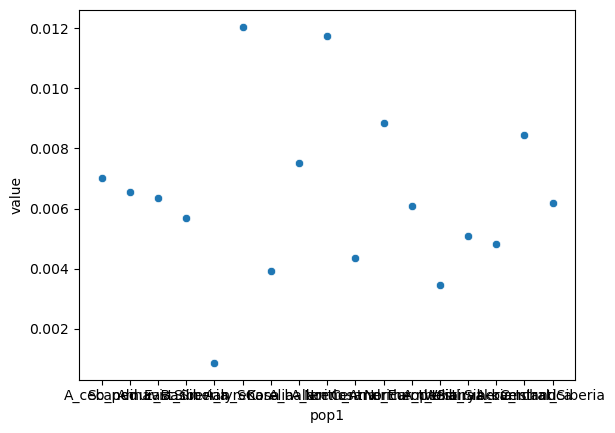

In [6]:
sns.scatterplot(x=pionly.pop1, y=pionly["value"])

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16],
 [Text(0, 0, 'A_ceb_ped'),
  Text(1, 0, 'Scandinavia'),
  Text(2, 0, 'Amur_Basin'),
  Text(3, 0, 'East_Siberia'),
  Text(4, 0, 'Siberian_SC'),
  Text(5, 0, 'A_lyrenosa'),
  Text(6, 0, 'Karelia'),
  Text(7, 0, 'A_halleri'),
  Text(8, 0, 'A_arenosa'),
  Text(9, 0, 'North_America'),
  Text(10, 0, 'Central_Europe'),
  Text(11, 0, 'Northern_Ural'),
  Text(12, 0, 'A_thaliana'),
  Text(13, 0, 'West_Siberia'),
  Text(14, 0, 'Sibiryakov_Island'),
  Text(15, 0, 'A_kamchatica'),
  Text(16, 0, 'Central_Siberia')])

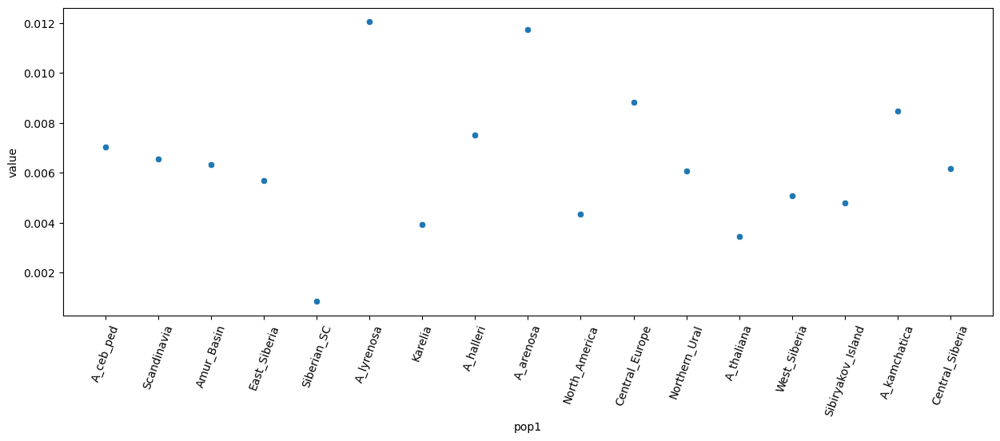

In [7]:
fig = plt.figure(figsize=(15, 5))
sns.scatterplot(x=pionly.pop1, y=pionly["value"])
plt.xticks(rotation=70)

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13],
 [Text(0, 0, 'Amur_Basin'),
  Text(1, 0, 'Central_Europe'),
  Text(2, 0, 'Central_Siberia'),
  Text(3, 0, 'North_America'),
  Text(4, 0, 'West_Siberia'),
  Text(5, 0, 'A_thaliana'),
  Text(6, 0, 'Siberian_SC'),
  Text(7, 0, 'A_lyrenosa'),
  Text(8, 0, 'Karelia'),
  Text(9, 0, 'Northern_Ural'),
  Text(10, 0, 'Scandinavia'),
  Text(11, 0, 'East_Siberia'),
  Text(12, 0, 'Sibiryakov_Island'),
  Text(13, 0, 'A_kamchatica')])

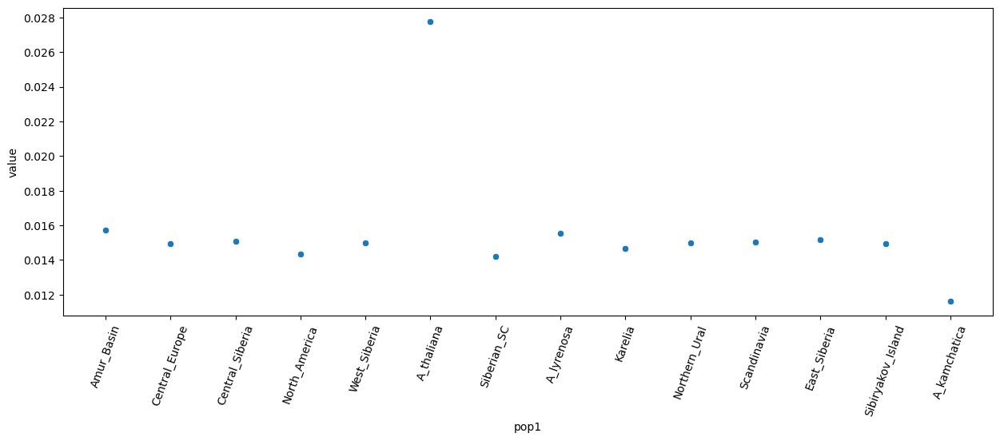

In [8]:
fig = plt.figure(figsize=(15, 5))
sns.scatterplot(x=piawka[(piawka["metric"] == "Dxy") & (piawka.pop2 == "A_halleri")].pop1, y=piawka[(piawka["metric"] == "Dxy") & (piawka.pop2 == "A_halleri")]["value"])
plt.xticks(rotation=70)

In [72]:
piawka_w = pd.read_csv("../Eur_lyrata/piawka/filtered_pi_wind", sep="\t")
piawka_w

,Chr,start,end,nSites,pop1,pop2,nUsed,metric,value,numerator,denominator,nGeno,nMiss
0,scaffold_1,1,100000,100000,A_ceb_ped,.,34426,pi,0.004939,14472,2930072,331688,12572
1,scaffold_1,1,100000,100000,Scandinavia,.,37566,pi,0.003768,7125286,1891225872,8276048,1195304
2,scaffold_1,1,100000,100000,Amur_Basin,.,33591,pi,0.003164,66272,20946560,848184,25182
3,scaffold_1,1,100000,100000,East_Siberia,.,37830,pi,0.002974,7094334,2385652636,8940428,2319300
4,scaffold_1,1,100000,100000,Siberian_SC,.,38492,pi,0.001736,13606,7835300,545100,114860
...,...,...,...,...,...,...,...,...,...,...,...,...,...
305305,scaffold_8,21400001,21469731,69731,Sibiryakov_Island,Karelia,27570,Dxy,0.001965,24254,12345816,1304032,169826
305306,scaffold_8,21400001,21469731,69731,West_Siberia,A_ceb_ped,26607,Dxy,0.008881,688656,77541752,8531400,2112390
305307,scaffold_8,21400001,21469731,69731,A_thaliana,A_ceb_ped,24989,Dxy,0.024654,101382,4112116,690326,48770
305308,scaffold_8,21400001,21469731,69731,West_Siberia,Siberian_SC,28259,Dxy,0.002224,288574,129739548,8698604,2173434


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
 [Text(0, 0, 'Amur_Basin'),
  Text(1, 0, 'Central_Europe'),
  Text(2, 0, 'Central_Siberia'),
  Text(3, 0, 'North_America'),
  Text(4, 0, 'West_Siberia'),
  Text(5, 0, 'Siberian_SC'),
  Text(6, 0, 'A_lyrenosa'),
  Text(7, 0, 'Karelia'),
  Text(8, 0, 'Northern_Ural'),
  Text(9, 0, 'Scandinavia'),
  Text(10, 0, 'East_Siberia'),
  Text(11, 0, 'Sibiryakov_Island'),
  Text(12, 0, 'A_kamchatica')])

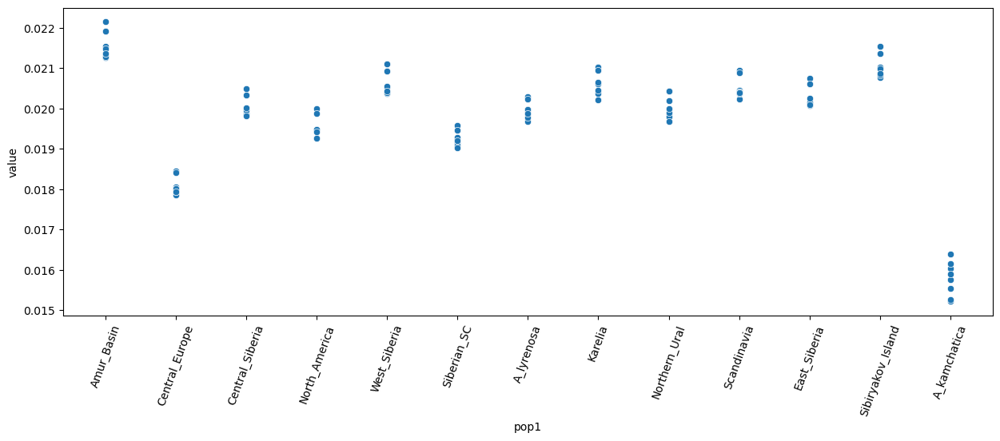

In [31]:
fig = plt.figure(figsize=(15, 5))
sns.scatterplot(x=piawka[(piawka["metric"] == "Dxy") & (piawka.pop2 == "A_halleri") & (piawka.pop1 != "A_thaliana")].pop1, y=piawka[(piawka["metric"] == "Dxy") & (piawka.pop2 == "A_halleri")& (piawka.pop1 != "A_thaliana")]["value"])
plt.xticks(rotation=70)

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11],
 [Text(0, 0, 'Sibiryakov_Island'),
  Text(1, 0, 'Northern_Ural'),
  Text(2, 0, 'Central_Siberia'),
  Text(3, 0, 'Scandinavia'),
  Text(4, 0, 'Karelia'),
  Text(5, 0, 'North_America'),
  Text(6, 0, 'West_Siberia'),
  Text(7, 0, 'Siberian_SC'),
  Text(8, 0, 'Amur_Basin'),
  Text(9, 0, 'A_lyrenosa'),
  Text(10, 0, 'East_Siberia'),
  Text(11, 0, 'Central_Europe')])

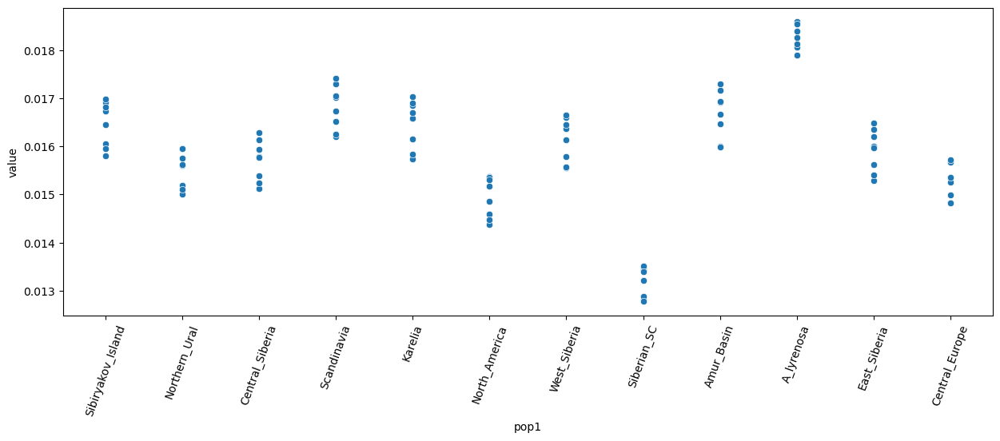

In [32]:
fig = plt.figure(figsize=(15, 5))
sns.scatterplot(x=piawka[(piawka["metric"] == "Dxy") & (piawka.pop2 == "A_kamchatica") & (piawka.pop1 != "A_thaliana")].pop1, y=piawka[(piawka["metric"] == "Dxy") & (piawka.pop2 == "A_kamchatica")& (piawka.pop1 != "A_thaliana")]["value"])
plt.xticks(rotation=70)

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14],
 [Text(0, 0, 'Scandinavia'),
  Text(1, 0, 'East_Siberia'),
  Text(2, 0, 'Northern_Ural'),
  Text(3, 0, 'A_ceb_ped'),
  Text(4, 0, 'Sibiryakov_Island'),
  Text(5, 0, 'A_halleri'),
  Text(6, 0, 'A_kamchatica'),
  Text(7, 0, 'Central_Siberia'),
  Text(8, 0, 'Amur_Basin'),
  Text(9, 0, 'Central_Europe'),
  Text(10, 0, 'North_America'),
  Text(11, 0, 'West_Siberia'),
  Text(12, 0, 'Karelia'),
  Text(13, 0, 'Siberian_SC'),
  Text(14, 0, 'A_lyrenosa')])

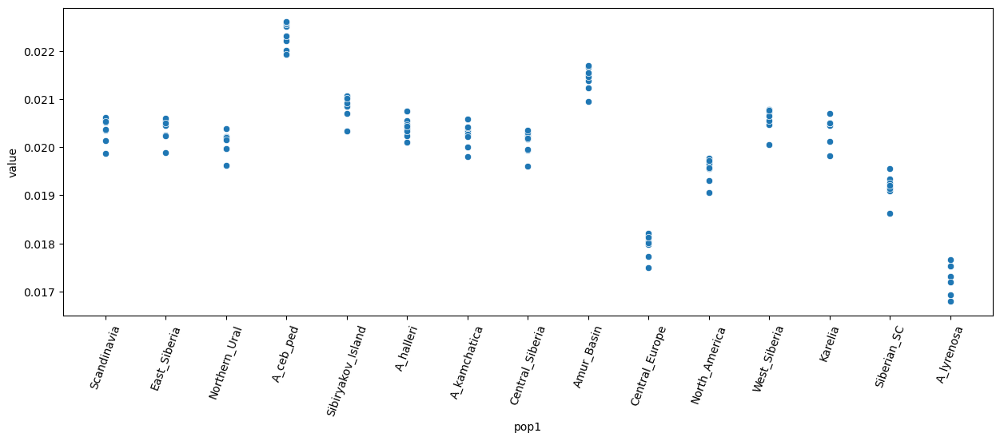

In [33]:
fig = plt.figure(figsize=(15, 5))
sns.scatterplot(x=piawka[(piawka["metric"] == "Dxy") & (piawka.pop2 == "A_arenosa") & (piawka.pop1 != "A_thaliana")].pop1, y=piawka[(piawka["metric"] == "Dxy") & (piawka.pop2 == "A_arenosa")& (piawka.pop1 != "A_thaliana")]["value"])
plt.xticks(rotation=70)

In [73]:
pionly_sp = piawka_w[piawka_w["metric"] == "pi"]

/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='start', ylabel='value'>

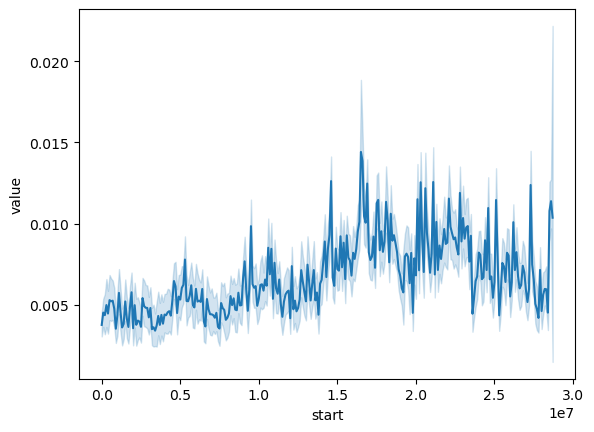

In [18]:
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_1"].start, y=pionly_w[pionly_w.Chr == "scaffold_1"]["value"])

/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packa

<Axes: xlabel='start', ylabel='value'>

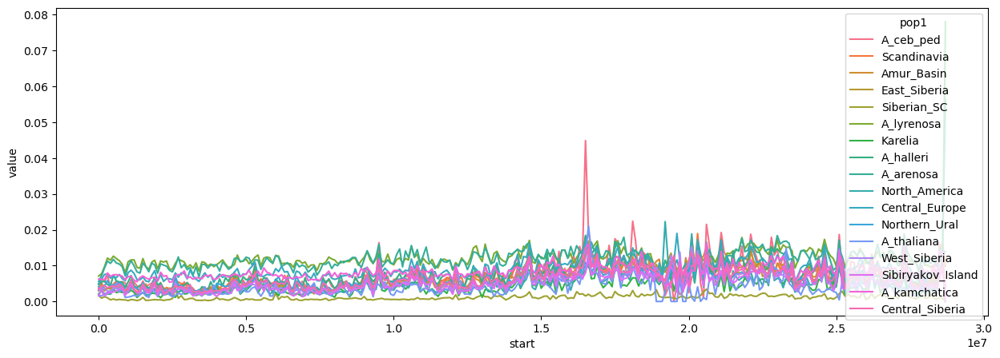

In [19]:
fig = plt.figure(figsize=(15, 5))
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_1"].start, y=pionly_w[pionly_w.Chr == "scaffold_1"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_1"].pop1)

In [26]:
species_list = ["Lyrata", "A_ceb_ped", "A_lyrenosa", "A_halleri", "A_arenosa", "A_thaliana", "A_kamchatica"]

In [29]:
pionly_sp = pionly_w[pionly_w.pop1.isin(species_list) == True]

/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packa

<Axes: xlabel='start', ylabel='value'>

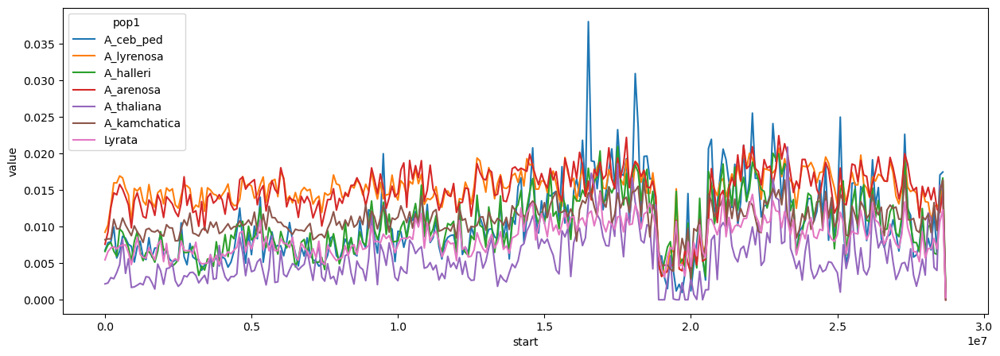

In [43]:
fig = plt.figure(figsize=(15, 5))
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_1"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_1"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_1"].pop1)

/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packa

<Axes: xlabel='start', ylabel='value'>

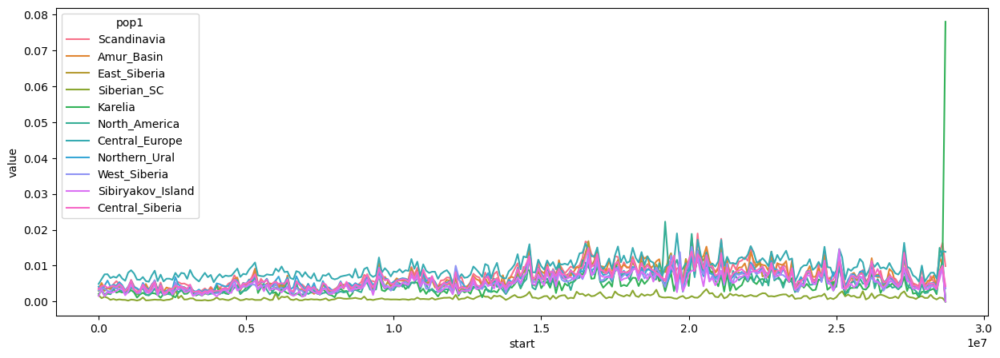

In [22]:
fig = plt.figure(figsize=(15, 5))
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_1"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_1"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_1"].pop1)

/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packa

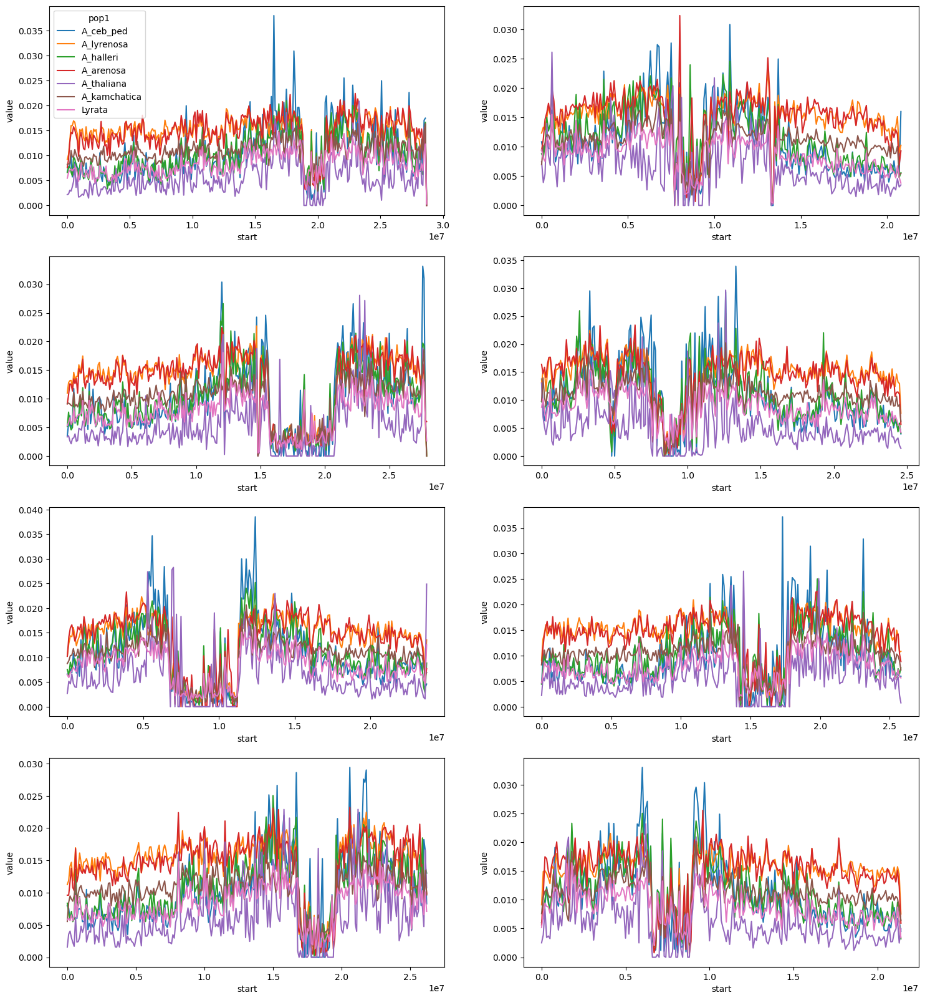

In [49]:
fig = plt.figure(figsize=(18, 20))
ax = fig.add_subplot(4,2,1)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_1"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_1"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_1"].pop1)
ax = fig.add_subplot(4,2,2)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_2"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_2"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_2"].pop1, legend=False)
ax = fig.add_subplot(4,2,3)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_3"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_3"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_3"].pop1, legend=False)
ax = fig.add_subplot(4,2,4)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_4"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_4"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_4"].pop1, legend=False)
ax = fig.add_subplot(4,2,5)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_5"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_5"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_5"].pop1, legend=False)
ax = fig.add_subplot(4,2,6)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_6"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_6"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_6"].pop1, legend=False)
ax = fig.add_subplot(4,2,7)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_7"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_7"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_7"].pop1, legend=False)
ax = fig.add_subplot(4,2,8)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_8"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_8"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_8"].pop1, legend=False)
fig.savefig("Piawka_species.pdf")

/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packa

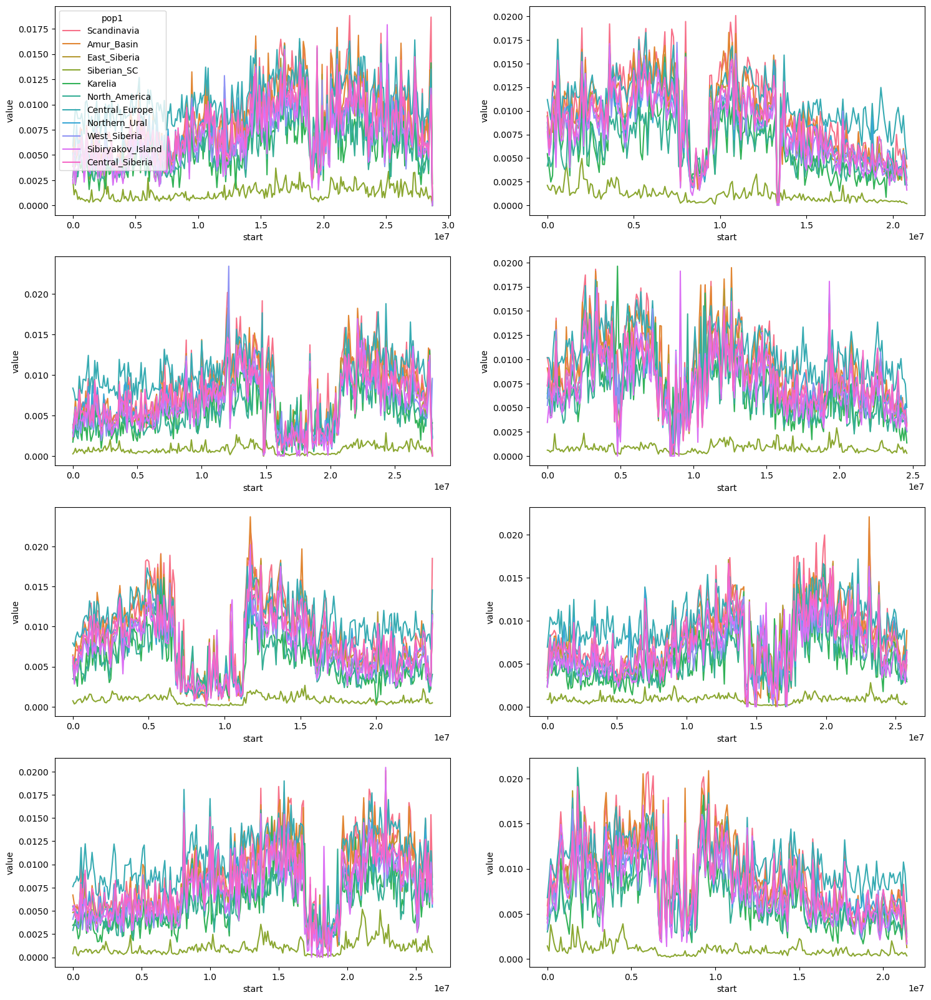

In [52]:
fig = plt.figure(figsize=(18, 20))
ax = fig.add_subplot(4,2,1)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_1"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_1"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_1"].pop1)
ax = fig.add_subplot(4,2,2)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_2"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_2"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_2"].pop1, legend=False)
ax = fig.add_subplot(4,2,3)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_3"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_3"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_3"].pop1, legend=False)
ax = fig.add_subplot(4,2,4)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_4"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_4"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_4"].pop1, legend=False)
ax = fig.add_subplot(4,2,5)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_5"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_5"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_5"].pop1, legend=False)
ax = fig.add_subplot(4,2,6)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_6"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_6"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_6"].pop1, legend=False)
ax = fig.add_subplot(4,2,7)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_7"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_7"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_7"].pop1, legend=False)
ax = fig.add_subplot(4,2,8)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_8"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_8"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_8"].pop1, legend=False)
fig.savefig("Piawka_pops.pdf")

/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packa

<Axes: xlabel='start', ylabel='value'>

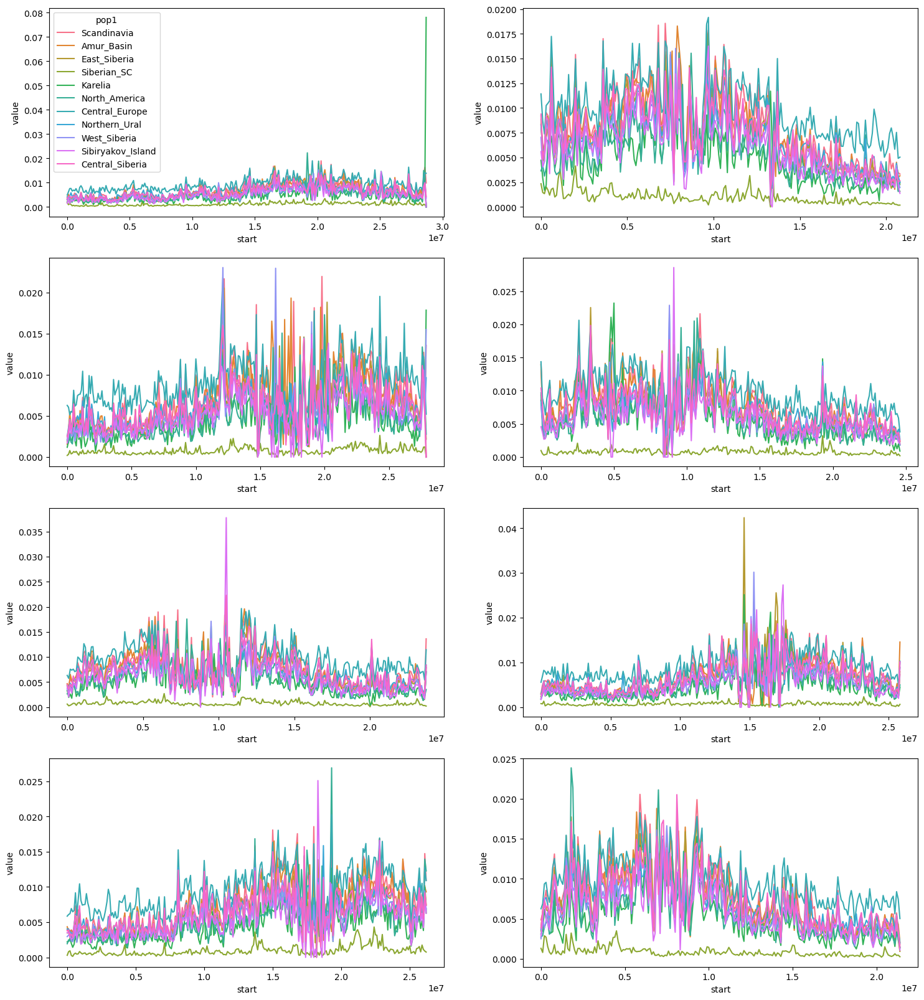

In [23]:
fig = plt.figure(figsize=(18, 20))
ax = fig.add_subplot(4,2,1)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_1"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_1"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_1"].pop1)
ax = fig.add_subplot(4,2,2)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_2"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_2"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_2"].pop1, legend=False)
ax = fig.add_subplot(4,2,3)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_3"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_3"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_3"].pop1, legend=False)
ax = fig.add_subplot(4,2,4)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_4"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_4"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_4"].pop1, legend=False)
ax = fig.add_subplot(4,2,5)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_5"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_5"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_5"].pop1, legend=False)
ax = fig.add_subplot(4,2,6)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_6"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_6"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_6"].pop1, legend=False)
ax = fig.add_subplot(4,2,7)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_7"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_7"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_7"].pop1, legend=False)
ax = fig.add_subplot(4,2,8)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_8"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_8"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_8"].pop1, legend=False)


/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packa

<Axes: xlabel='start', ylabel='value'>

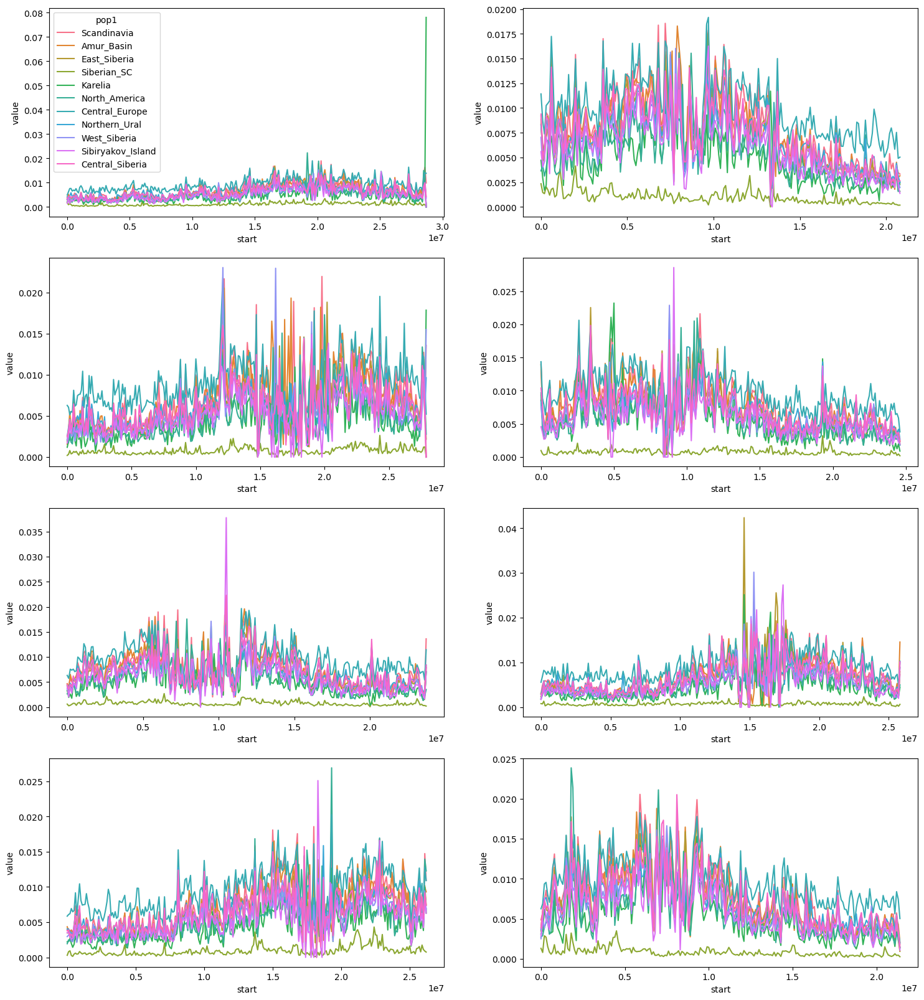

In [24]:
fig = plt.figure(figsize=(18, 20))
ax = fig.add_subplot(4,2,1)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_1"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_1"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_1"].pop1)
ax = fig.add_subplot(4,2,2)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_2"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_2"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_2"].pop1, legend=False)
ax = fig.add_subplot(4,2,3)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_3"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_3"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_3"].pop1, legend=False)
ax = fig.add_subplot(4,2,4)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_4"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_4"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_4"].pop1, legend=False)
ax = fig.add_subplot(4,2,5)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_5"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_5"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_5"].pop1, legend=False)
ax = fig.add_subplot(4,2,6)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_6"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_6"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_6"].pop1, legend=False)
ax = fig.add_subplot(4,2,7)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_7"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_7"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_7"].pop1, legend=False)
ax = fig.add_subplot(4,2,8)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_8"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_8"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_8"].pop1, legend=False)


/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packa

<Axes: xlabel='start', ylabel='value'>

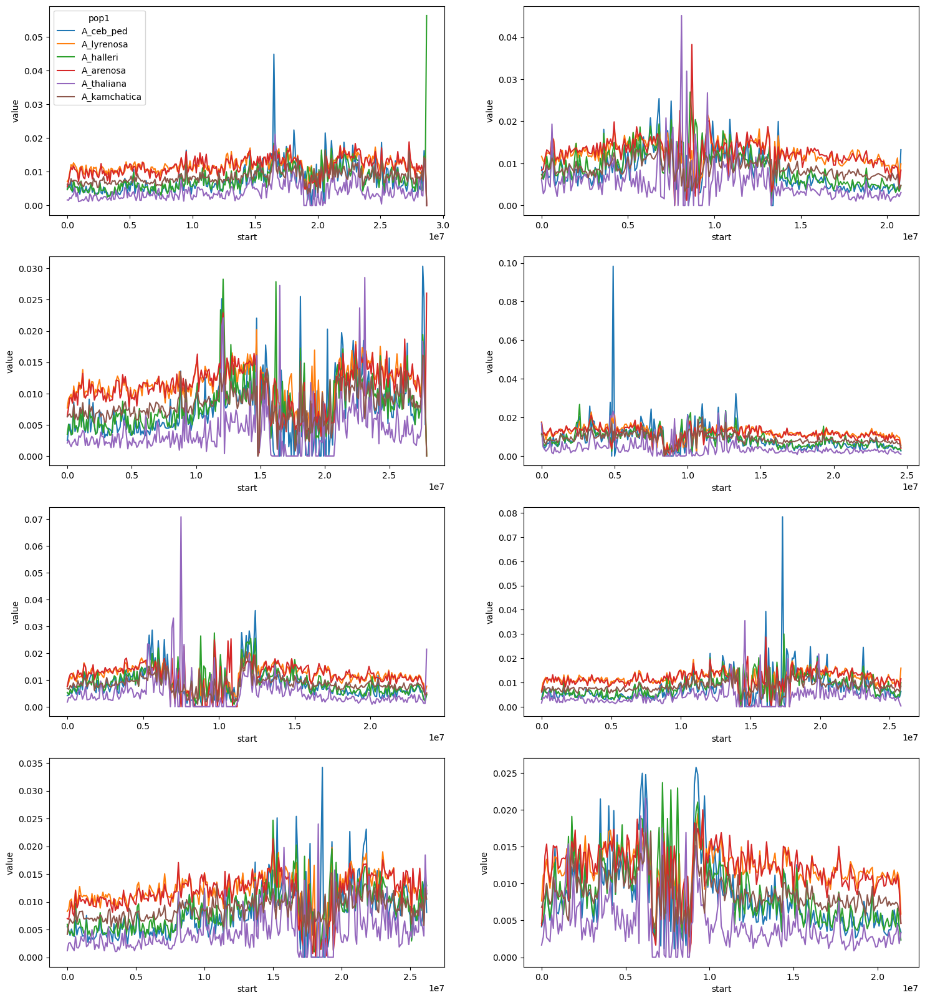

In [30]:
fig = plt.figure(figsize=(18, 20))
ax = fig.add_subplot(4,2,1)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_1"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_1"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_1"].pop1)
ax = fig.add_subplot(4,2,2)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_2"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_2"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_2"].pop1, legend=False)
ax = fig.add_subplot(4,2,3)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_3"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_3"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_3"].pop1, legend=False)
ax = fig.add_subplot(4,2,4)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_4"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_4"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_4"].pop1, legend=False)
ax = fig.add_subplot(4,2,5)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_5"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_5"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_5"].pop1, legend=False)
ax = fig.add_subplot(4,2,6)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_6"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_6"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_6"].pop1, legend=False)
ax = fig.add_subplot(4,2,7)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_7"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_7"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_7"].pop1, legend=False)
ax = fig.add_subplot(4,2,8)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_8"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_8"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_8"].pop1, legend=False)


In [3]:
piawka_w = pd.read_csv("../Eur_lyrata/piawka/Total_pi_wind_lyr.tsv", sep="\t")
piawka_w

,Chr,start,end,nSites,pop1,pop2,nUsed,metric,value,numerator,denominator,nGeno,nMiss
0,scaffold_1,1,100000,100000,Lyrata,.,50197,pi,0.005460,977344992,178990983310,86328678,28934350
1,scaffold_1,100001,200000,100000,Lyrata,.,61930,pi,0.006577,907259944,137945802752,72064760,69090468
2,scaffold_1,200001,300000,100000,Lyrata,.,44726,pi,0.007087,1177733610,166192105430,80232926,22681420
3,scaffold_1,300001,400000,100000,Lyrata,.,37727,pi,0.007250,1113472946,153590385768,73270072,13743064
4,scaffold_1,400001,500000,100000,Lyrata,.,45561,pi,0.006950,1188900548,171072511996,82245020,22466760
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1994,scaffold_8,21000001,21100000,100000,Lyrata,.,50620,pi,0.007923,1284809532,162167202760,81352968,35106718
1995,scaffold_8,21100001,21200000,100000,Lyrata,.,42939,pi,0.005230,801948818,153349734840,74645568,24336166
1996,scaffold_8,21200001,21300000,100000,Lyrata,.,41824,pi,0.008717,1408940706,161632366500,77695996,18904788
1997,scaffold_8,21300001,21400000,100000,Lyrata,.,47112,pi,0.006038,1030464162,170661207110,82569070,26114062


/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='start', ylabel='value'>

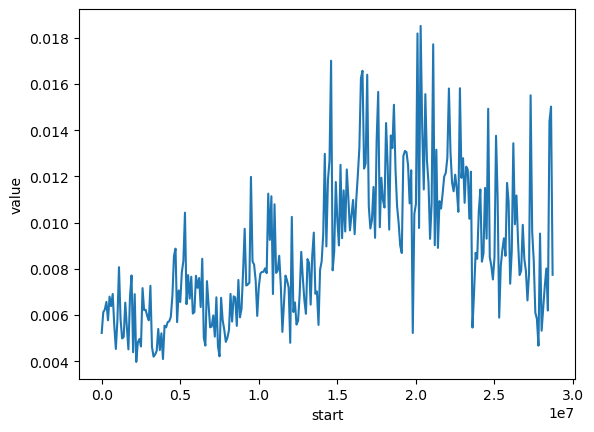

In [33]:
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_1"].start, y=pionly_w[pionly_w.Chr == "scaffold_1"]["value"])

/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: us

<Axes: xlabel='start', ylabel='value'>

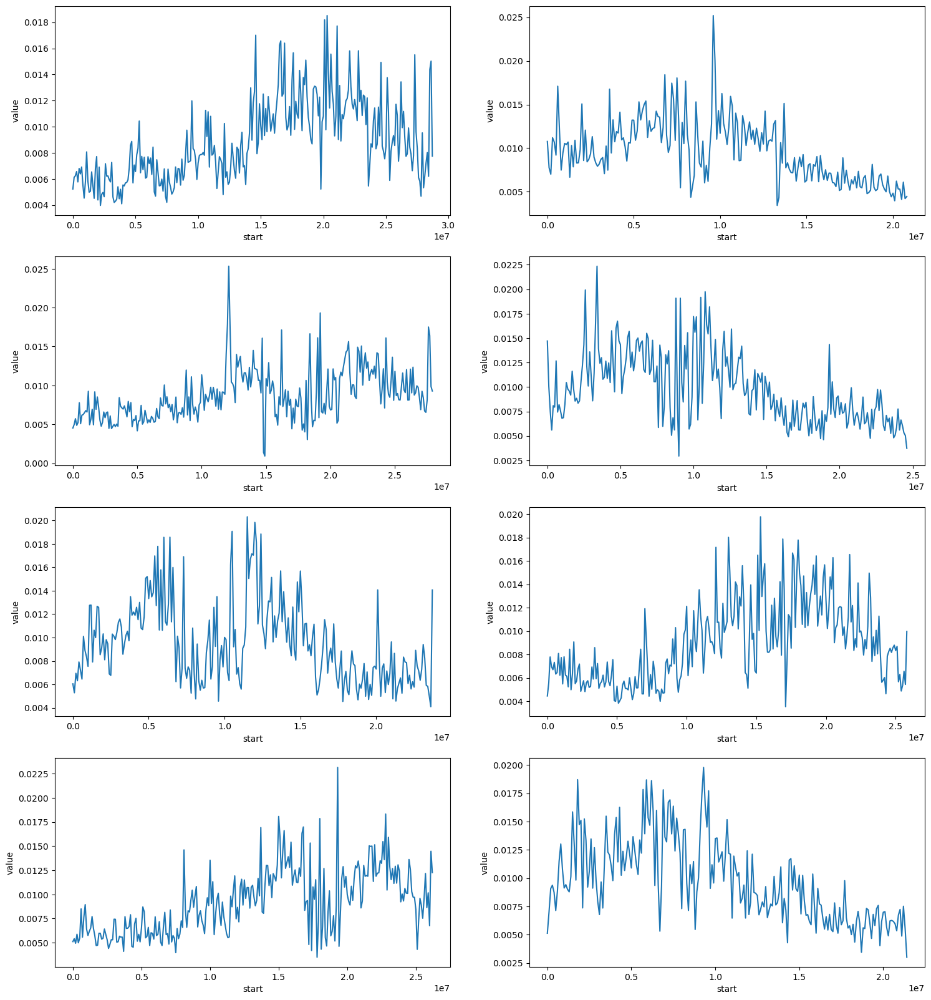

In [37]:
fig = plt.figure(figsize=(18, 20))
ax = fig.add_subplot(4,2,1)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_1"].start, y=pionly_w[pionly_w.Chr == "scaffold_1"]["value"])
ax = fig.add_subplot(4,2,2)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_2"].start, y=pionly_w[pionly_w.Chr == "scaffold_2"]["value"], legend=False)
ax = fig.add_subplot(4,2,3)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_3"].start, y=pionly_w[pionly_w.Chr == "scaffold_3"]["value"], legend=False)
ax = fig.add_subplot(4,2,4)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_4"].start, y=pionly_w[pionly_w.Chr == "scaffold_4"]["value"], legend=False)
ax = fig.add_subplot(4,2,5)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_5"].start, y=pionly_w[pionly_w.Chr == "scaffold_5"]["value"], legend=False)
ax = fig.add_subplot(4,2,6)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_6"].start, y=pionly_w[pionly_w.Chr == "scaffold_6"]["value"], legend=False)
ax = fig.add_subplot(4,2,7)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_7"].start, y=pionly_w[pionly_w.Chr == "scaffold_7"]["value"], legend=False)
ax = fig.add_subplot(4,2,8)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_8"].start, y=pionly_w[pionly_w.Chr == "scaffold_8"]["value"], legend=False)


/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: us

<Axes: xlabel='start', ylabel='value'>

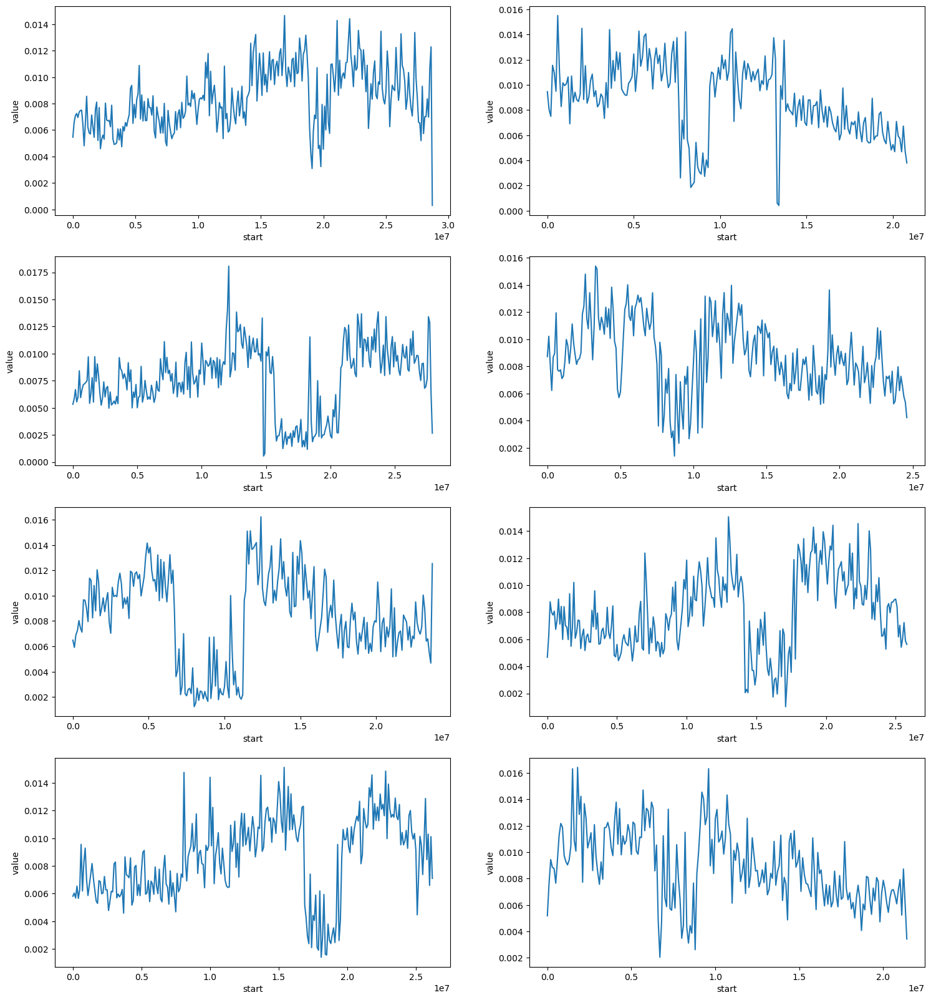

In [42]:
fig = plt.figure(figsize=(18, 20))
ax = fig.add_subplot(4,2,1)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_1"].start, y=pionly_w[pionly_w.Chr == "scaffold_1"]["value"])
ax = fig.add_subplot(4,2,2)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_2"].start, y=pionly_w[pionly_w.Chr == "scaffold_2"]["value"], legend=False)
ax = fig.add_subplot(4,2,3)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_3"].start, y=pionly_w[pionly_w.Chr == "scaffold_3"]["value"], legend=False)
ax = fig.add_subplot(4,2,4)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_4"].start, y=pionly_w[pionly_w.Chr == "scaffold_4"]["value"], legend=False)
ax = fig.add_subplot(4,2,5)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_5"].start, y=pionly_w[pionly_w.Chr == "scaffold_5"]["value"], legend=False)
ax = fig.add_subplot(4,2,6)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_6"].start, y=pionly_w[pionly_w.Chr == "scaffold_6"]["value"], legend=False)
ax = fig.add_subplot(4,2,7)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_7"].start, y=pionly_w[pionly_w.Chr == "scaffold_7"]["value"], legend=False)
ax = fig.add_subplot(4,2,8)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_8"].start, y=pionly_w[pionly_w.Chr == "scaffold_8"]["value"], legend=False)


In [75]:
pi_thaliana2 = pionly_sp[pionly_sp.pop1 == "A_thaliana"]

/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packa

<Axes: xlabel='start', ylabel='value'>

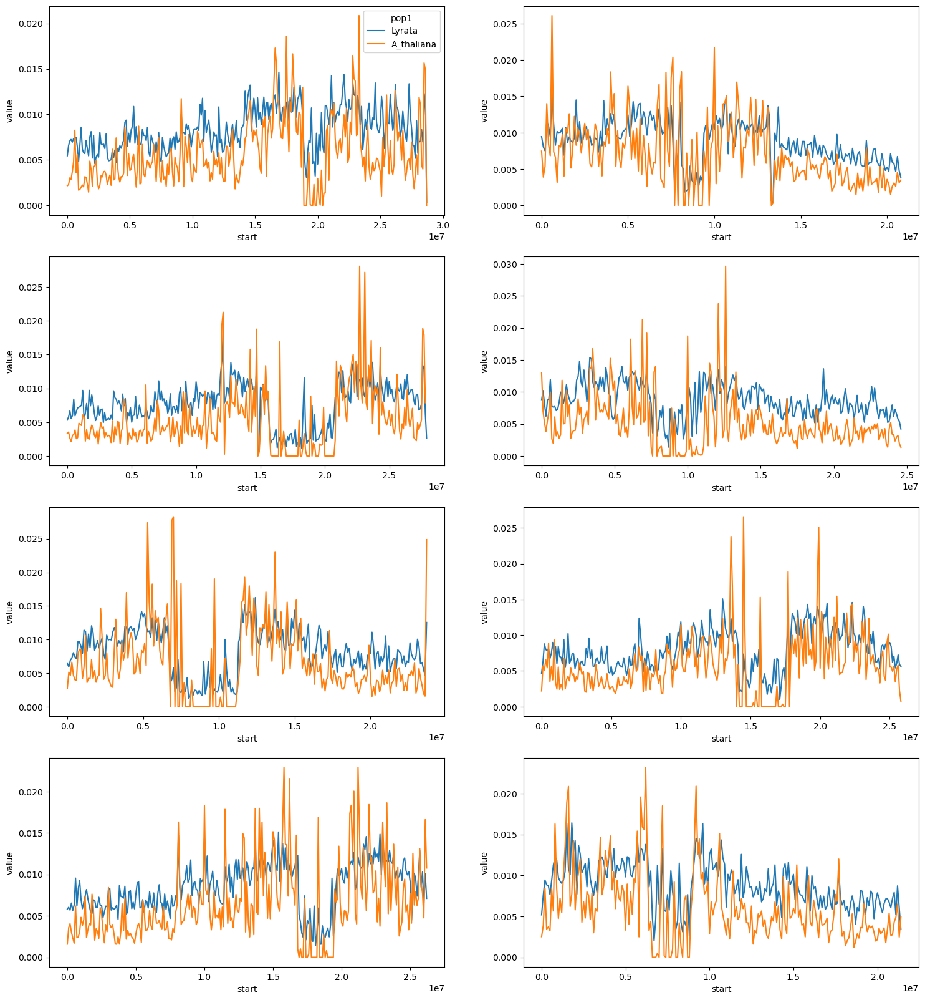

In [56]:
fig = plt.figure(figsize=(18, 20))
ax = fig.add_subplot(4,2,1)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_1"].start, y=pionly_w[pionly_w.Chr == "scaffold_1"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_1"].pop1)
ax = fig.add_subplot(4,2,2)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_2"].start, y=pionly_w[pionly_w.Chr == "scaffold_2"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_2"].pop1, legend=False)
ax = fig.add_subplot(4,2,3)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_3"].start, y=pionly_w[pionly_w.Chr == "scaffold_3"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_3"].pop1, legend=False)
ax = fig.add_subplot(4,2,4)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_4"].start, y=pionly_w[pionly_w.Chr == "scaffold_4"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_4"].pop1, legend=False)
ax = fig.add_subplot(4,2,5)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_5"].start, y=pionly_w[pionly_w.Chr == "scaffold_5"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_5"].pop1, legend=False)
ax = fig.add_subplot(4,2,6)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_6"].start, y=pionly_w[pionly_w.Chr == "scaffold_6"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_6"].pop1, legend=False)
ax = fig.add_subplot(4,2,7)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_7"].start, y=pionly_w[pionly_w.Chr == "scaffold_7"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_7"].pop1, legend=False)
ax = fig.add_subplot(4,2,8)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_8"].start, y=pionly_w[pionly_w.Chr == "scaffold_8"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_8"].pop1, legend=False)


In [78]:
pionly_w = pd.concat([pionly_w, pi_thaliana2])

/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packa

<Axes: xlabel='start', ylabel='value'>

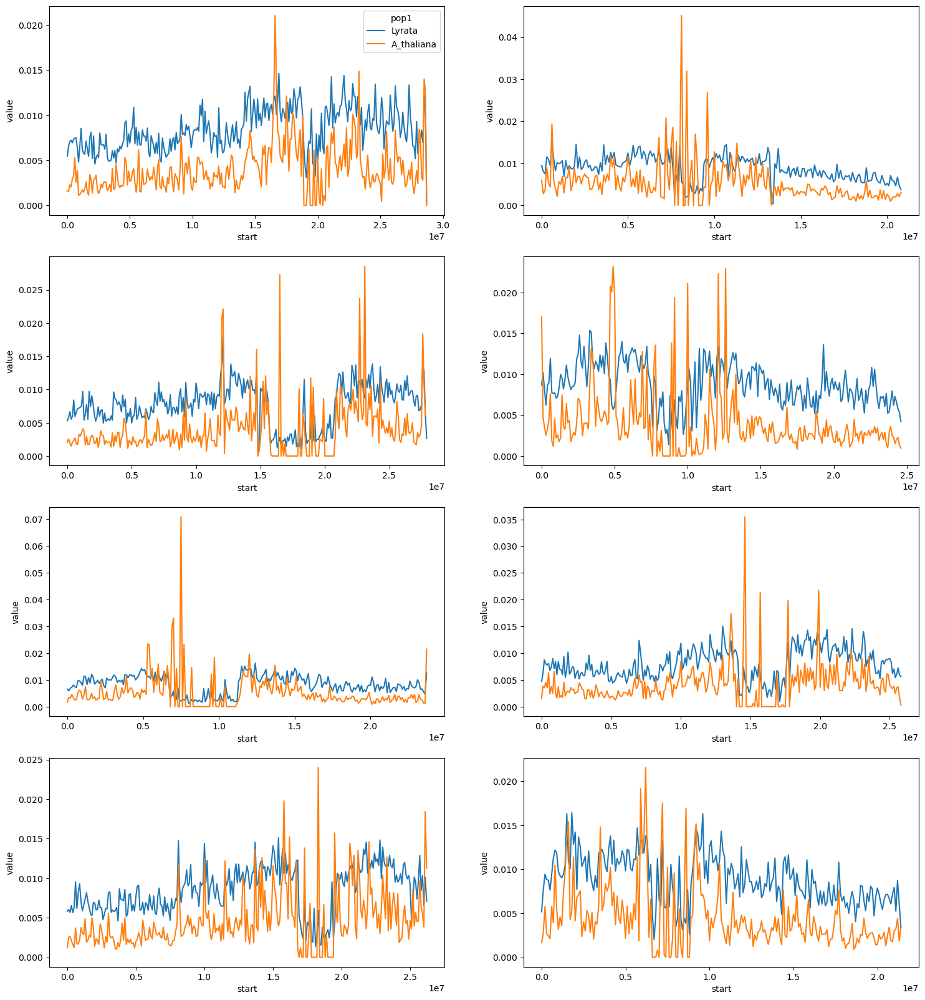

In [79]:
fig = plt.figure(figsize=(18, 20))
ax = fig.add_subplot(4,2,1)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_1"].start, y=pionly_w[pionly_w.Chr == "scaffold_1"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_1"].pop1)
ax = fig.add_subplot(4,2,2)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_2"].start, y=pionly_w[pionly_w.Chr == "scaffold_2"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_2"].pop1, legend=False)
ax = fig.add_subplot(4,2,3)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_3"].start, y=pionly_w[pionly_w.Chr == "scaffold_3"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_3"].pop1, legend=False)
ax = fig.add_subplot(4,2,4)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_4"].start, y=pionly_w[pionly_w.Chr == "scaffold_4"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_4"].pop1, legend=False)
ax = fig.add_subplot(4,2,5)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_5"].start, y=pionly_w[pionly_w.Chr == "scaffold_5"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_5"].pop1, legend=False)
ax = fig.add_subplot(4,2,6)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_6"].start, y=pionly_w[pionly_w.Chr == "scaffold_6"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_6"].pop1, legend=False)
ax = fig.add_subplot(4,2,7)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_7"].start, y=pionly_w[pionly_w.Chr == "scaffold_7"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_7"].pop1, legend=False)
ax = fig.add_subplot(4,2,8)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_8"].start, y=pionly_w[pionly_w.Chr == "scaffold_8"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_8"].pop1, legend=False)


In [4]:
pionly_w = piawka_w[piawka_w["metric"] == "pi"]

In [80]:
pionly_w = pionly_w[pionly_w["value"] < 0.017]

/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packa

<Axes: xlabel='start', ylabel='value'>

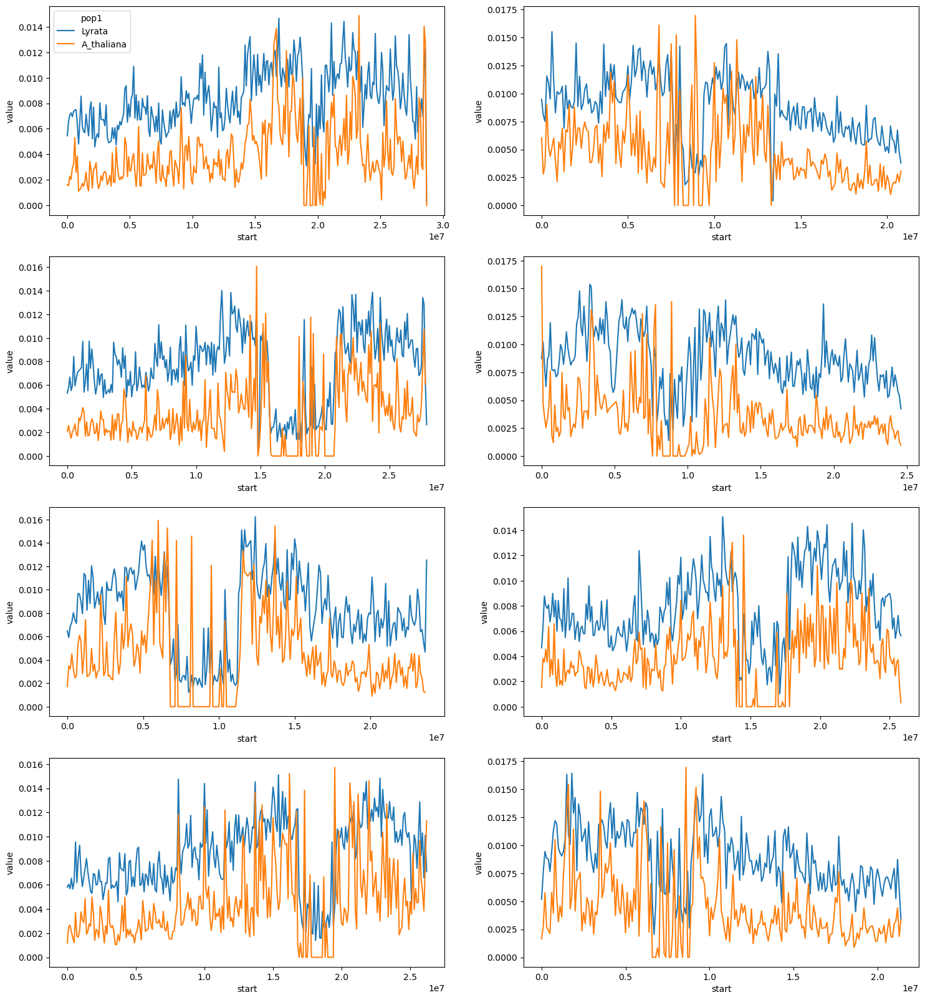

In [81]:
fig = plt.figure(figsize=(18, 20))
ax = fig.add_subplot(4,2,1)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_1"].start, y=pionly_w[pionly_w.Chr == "scaffold_1"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_1"].pop1)
ax = fig.add_subplot(4,2,2)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_2"].start, y=pionly_w[pionly_w.Chr == "scaffold_2"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_2"].pop1, legend=False)
ax = fig.add_subplot(4,2,3)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_3"].start, y=pionly_w[pionly_w.Chr == "scaffold_3"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_3"].pop1, legend=False)
ax = fig.add_subplot(4,2,4)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_4"].start, y=pionly_w[pionly_w.Chr == "scaffold_4"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_4"].pop1, legend=False)
ax = fig.add_subplot(4,2,5)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_5"].start, y=pionly_w[pionly_w.Chr == "scaffold_5"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_5"].pop1, legend=False)
ax = fig.add_subplot(4,2,6)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_6"].start, y=pionly_w[pionly_w.Chr == "scaffold_6"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_6"].pop1, legend=False)
ax = fig.add_subplot(4,2,7)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_7"].start, y=pionly_w[pionly_w.Chr == "scaffold_7"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_7"].pop1, legend=False)
ax = fig.add_subplot(4,2,8)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_8"].start, y=pionly_w[pionly_w.Chr == "scaffold_8"]["value"], hue=pionly_w[pionly_w.Chr == "scaffold_8"].pop1, legend=False)


In [85]:
pionly_w = pionly_w[pionly_w.pop1 == "Lyrata"]

/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: us

<Axes: xlabel='start', ylabel='nGeno'>

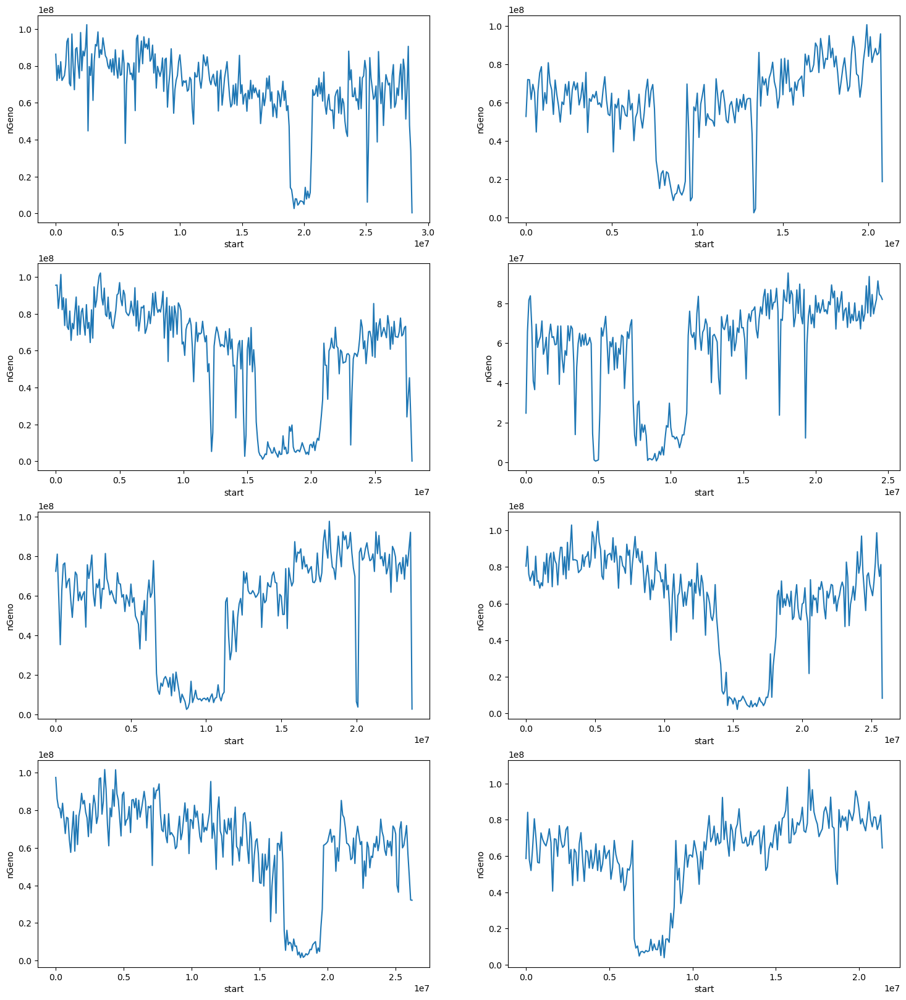

In [87]:
fig = plt.figure(figsize=(18, 20))
ax = fig.add_subplot(4,2,1)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_1"].start, y=pionly_w[pionly_w.Chr == "scaffold_1"]["nGeno"])
ax = fig.add_subplot(4,2,2)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_2"].start, y=pionly_w[pionly_w.Chr == "scaffold_2"]["nGeno"], legend=False)
ax = fig.add_subplot(4,2,3)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_3"].start, y=pionly_w[pionly_w.Chr == "scaffold_3"]["nGeno"], legend=False)
ax = fig.add_subplot(4,2,4)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_4"].start, y=pionly_w[pionly_w.Chr == "scaffold_4"]["nGeno"], legend=False)
ax = fig.add_subplot(4,2,5)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_5"].start, y=pionly_w[pionly_w.Chr == "scaffold_5"]["nGeno"], legend=False)
ax = fig.add_subplot(4,2,6)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_6"].start, y=pionly_w[pionly_w.Chr == "scaffold_6"]["nGeno"], legend=False)
ax = fig.add_subplot(4,2,7)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_7"].start, y=pionly_w[pionly_w.Chr == "scaffold_7"]["nGeno"], legend=False)
ax = fig.add_subplot(4,2,8)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_8"].start, y=pionly_w[pionly_w.Chr == "scaffold_8"]["nGeno"], legend=False)


/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: us

<Axes: xlabel='start', ylabel='nMiss'>

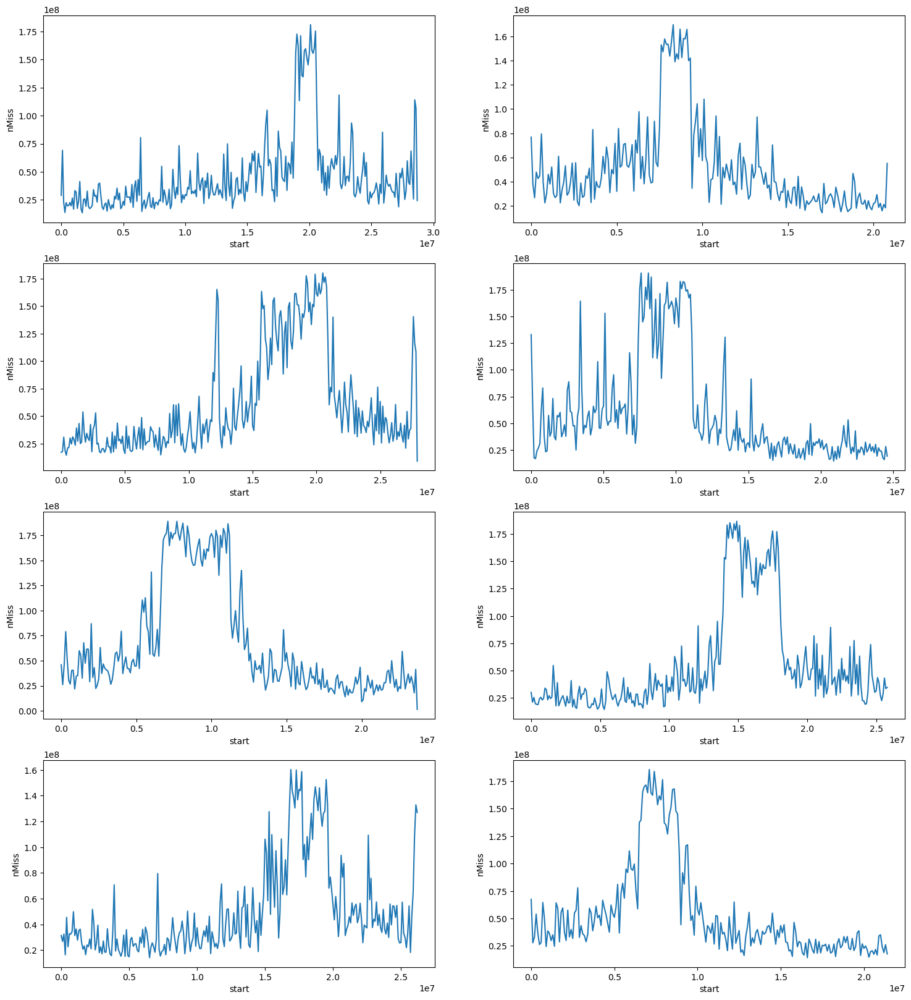

In [88]:
fig = plt.figure(figsize=(18, 20))
ax = fig.add_subplot(4,2,1)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_1"].start, y=pionly_w[pionly_w.Chr == "scaffold_1"]["nMiss"])
ax = fig.add_subplot(4,2,2)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_2"].start, y=pionly_w[pionly_w.Chr == "scaffold_2"]["nMiss"], legend=False)
ax = fig.add_subplot(4,2,3)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_3"].start, y=pionly_w[pionly_w.Chr == "scaffold_3"]["nMiss"], legend=False)
ax = fig.add_subplot(4,2,4)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_4"].start, y=pionly_w[pionly_w.Chr == "scaffold_4"]["nMiss"], legend=False)
ax = fig.add_subplot(4,2,5)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_5"].start, y=pionly_w[pionly_w.Chr == "scaffold_5"]["nMiss"], legend=False)
ax = fig.add_subplot(4,2,6)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_6"].start, y=pionly_w[pionly_w.Chr == "scaffold_6"]["nMiss"], legend=False)
ax = fig.add_subplot(4,2,7)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_7"].start, y=pionly_w[pionly_w.Chr == "scaffold_7"]["nMiss"], legend=False)
ax = fig.add_subplot(4,2,8)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_8"].start, y=pionly_w[pionly_w.Chr == "scaffold_8"]["nMiss"], legend=False)


In [ ]:
fig = plt.figure(figsize=(18, 20))
ax = fig.add_subplot(4,2,1)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_1"].start, y=pionly_w[pionly_w.Chr == "scaffold_1"]["value"])
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_1"].start, y=pionly_w[pionly_w.Chr == "scaffold_1"]["value"])
ax = fig.add_subplot(4,2,2)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_2"].start, y=pionly_w[pionly_w.Chr == "scaffold_2"]["value"], legend=False)
ax = fig.add_subplot(4,2,3)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_3"].start, y=pionly_w[pionly_w.Chr == "scaffold_3"]["value"], legend=False)
ax = fig.add_subplot(4,2,4)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_4"].start, y=pionly_w[pionly_w.Chr == "scaffold_4"]["value"], legend=False)
ax = fig.add_subplot(4,2,5)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_5"].start, y=pionly_w[pionly_w.Chr == "scaffold_5"]["value"], legend=False)
ax = fig.add_subplot(4,2,6)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_6"].start, y=pionly_w[pionly_w.Chr == "scaffold_6"]["value"], legend=False)
ax = fig.add_subplot(4,2,7)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_7"].start, y=pionly_w[pionly_w.Chr == "scaffold_7"]["value"], legend=False)
ax = fig.add_subplot(4,2,8)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_8"].start, y=pionly_w[pionly_w.Chr == "scaffold_8"]["value"], legend=False)


/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: us

(0.0, 36.0)

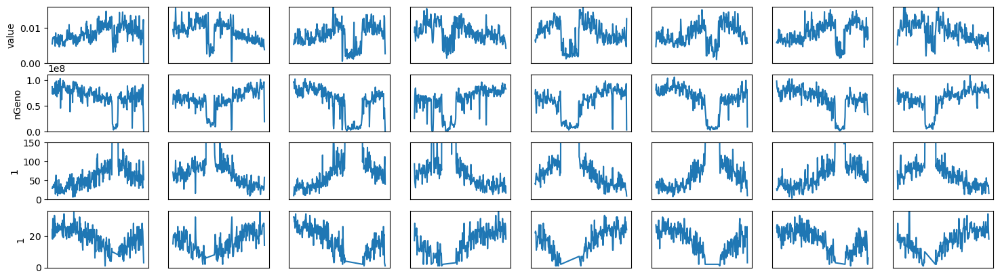

In [82]:
fig = plt.figure(figsize=(18, 5))
ax = fig.add_subplot(4,8,1)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_1"].start, y=pionly_w[pionly_w.Chr == "scaffold_1"]["value"])
ax.axes.get_xaxis().set_visible(False)
ax.set_ylim([0,0.016])
ax = fig.add_subplot(4,8,9)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_1"].start, y=pionly_w[pionly_w.Chr == "scaffold_1"]["nGeno"])
ax.axes.get_xaxis().set_visible(False)
ax.set_ylim([0,110000000])
ax = fig.add_subplot(4,8,17)
te_chr = tes[tes.iloc[:,0] == "scaffold_1"]
sns.lineplot(x=te_chr.iloc[:,1], y=te_chr.iloc[:,3])
ax.axes.get_xaxis().set_visible(False)
ax.set_ylim([0,150])
ax = fig.add_subplot(4,8,25)
te_chr = genes[genes.iloc[:,0] == "scaffold_1"]
sns.lineplot(x=te_chr.iloc[:,1], y=te_chr.iloc[:,3])
ax.set_ylim([0,36])
ax.axes.get_xaxis().set_visible(False)
ax = fig.add_subplot(4,8,2)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_2"].start, y=pionly_w[pionly_w.Chr == "scaffold_2"]["value"])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,0.016])
plt.xlabel
ax = fig.add_subplot(4,8,10)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_2"].start, y=pionly_w[pionly_w.Chr == "scaffold_2"]["nGeno"])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,110000000])
ax = fig.add_subplot(4,8,18)
te_chr = tes[tes.iloc[:,0] == "scaffold_2"]
sns.lineplot(x=te_chr.iloc[:,1], y=te_chr.iloc[:,3])
ax.set_ylim([0,150])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False) 
ax = fig.add_subplot(4,8,26)
te_chr = genes[genes.iloc[:,0] == "scaffold_2"]
sns.lineplot(x=te_chr.iloc[:,1], y=te_chr.iloc[:,3])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,36])
ax = fig.add_subplot(4,8,3)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_3"].start, y=pionly_w[pionly_w.Chr == "scaffold_3"]["value"])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,0.016])
ax = fig.add_subplot(4,8,11)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_3"].start, y=pionly_w[pionly_w.Chr == "scaffold_3"]["nGeno"])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False) 
ax.set_ylim([0,110000000])
ax = fig.add_subplot(4,8,19)
te_chr = tes[tes.iloc[:,0] == "scaffold_3"]
sns.lineplot(x=te_chr.iloc[:,1], y=te_chr.iloc[:,3])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,150])
ax = fig.add_subplot(4,8,27)
te_chr = genes[genes.iloc[:,0] == "scaffold_3"]
sns.lineplot(x=te_chr.iloc[:,1], y=te_chr.iloc[:,3])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,36])
ax = fig.add_subplot(4,8,4)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_4"].start, y=pionly_w[pionly_w.Chr == "scaffold_4"]["value"])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,0.016])
ax = fig.add_subplot(4,8,12)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_4"].start, y=pionly_w[pionly_w.Chr == "scaffold_4"]["nGeno"])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,110000000])
ax = fig.add_subplot(4,8,20)
te_chr = tes[tes.iloc[:,0] == "scaffold_4"]
sns.lineplot(x=te_chr.iloc[:,1], y=te_chr.iloc[:,3])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,150])
ax = fig.add_subplot(4,8,28)
te_chr = genes[genes.iloc[:,0] == "scaffold_4"]
sns.lineplot(x=te_chr.iloc[:,1], y=te_chr.iloc[:,3])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,36])
ax = fig.add_subplot(4,8,5)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_5"].start, y=pionly_w[pionly_w.Chr == "scaffold_5"]["value"])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,0.016])
ax = fig.add_subplot(4,8,13)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_5"].start, y=pionly_w[pionly_w.Chr == "scaffold_5"]["nGeno"])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,110000000])
ax = fig.add_subplot(4,8,21)
te_chr = tes[tes.iloc[:,0] == "scaffold_5"]
sns.lineplot(x=te_chr.iloc[:,1], y=te_chr.iloc[:,3])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,150])
ax = fig.add_subplot(4,8,29)
te_chr = genes[genes.iloc[:,0] == "scaffold_5"]
sns.lineplot(x=te_chr.iloc[:,1], y=te_chr.iloc[:,3])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,36])
ax = fig.add_subplot(4,8,6)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_6"].start, y=pionly_w[pionly_w.Chr == "scaffold_6"]["value"])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,0.016])
ax = fig.add_subplot(4,8,14)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_6"].start, y=pionly_w[pionly_w.Chr == "scaffold_6"]["nGeno"])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,110000000])
ax = fig.add_subplot(4,8,22)
te_chr = tes[tes.iloc[:,0] == "scaffold_6"]
sns.lineplot(x=te_chr.iloc[:,1], y=te_chr.iloc[:,3])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,150])
ax = fig.add_subplot(4,8,30)
te_chr = genes[genes.iloc[:,0] == "scaffold_6"]
sns.lineplot(x=te_chr.iloc[:,1], y=te_chr.iloc[:,3])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,36])
ax = fig.add_subplot(4,8,7)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_7"].start, y=pionly_w[pionly_w.Chr == "scaffold_7"]["value"])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,0.016])
ax = fig.add_subplot(4,8,15)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_7"].start, y=pionly_w[pionly_w.Chr == "scaffold_7"]["nGeno"])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,110000000])
ax = fig.add_subplot(4,8,23)
te_chr = tes[tes.iloc[:,0] == "scaffold_7"]
sns.lineplot(x=te_chr.iloc[:,1], y=te_chr.iloc[:,3])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,150])
ax = fig.add_subplot(4,8,31)
te_chr = genes[genes.iloc[:,0] == "scaffold_7"]
sns.lineplot(x=te_chr.iloc[:,1], y=te_chr.iloc[:,3])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,36])
ax = fig.add_subplot(4,8,8)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_8"].start, y=pionly_w[pionly_w.Chr == "scaffold_8"]["value"])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,0.016])
ax = fig.add_subplot(4,8,16)
sns.lineplot(x=pionly_w[pionly_w.Chr == "scaffold_8"].start, y=pionly_w[pionly_w.Chr == "scaffold_8"]["nGeno"])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,110000000])
ax = fig.add_subplot(4,8,24)
te_chr = tes[tes.iloc[:,0] == "scaffold_8"]
sns.lineplot(x=te_chr.iloc[:,1], y=te_chr.iloc[:,3])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,150])
ax = fig.add_subplot(4,8,32)
te_chr = genes[genes.iloc[:,0] == "scaffold_8"]
sns.lineplot(x=te_chr.iloc[:,1], y=te_chr.iloc[:,3])
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_ylim([0,36])

In [63]:
tes = pd.read_csv("mabs_assemblies/edta/NT1_220222.fasta_TEs/EDTA/NT1_220222.fasta.mod.EDTA.TEanno.gff3", sep="\t", header=None, skiprows=6)
tes.head()

,0,1,2,3,4,5,6,7,8
0,scaffold_1,EDTA,helitron,57,193,346,+,.,ID=TE_homo_0;Name=TE_00000778;Classification=D...
1,scaffold_1,EDTA,helitron,10919,12077,8011,+,.,ID=TE_homo_1;Name=TE_00000385;Classification=D...
2,scaffold_1,EDTA,helitron,12252,12589,2709,+,.,ID=TE_homo_2;Name=TE_00000385;Classification=D...
3,scaffold_1,EDTA,PIF_Harbinger_TIR_transposon,12634,12867,1185,+,.,ID=TE_homo_3;Name=TE_00001928;Classification=D...
4,scaffold_1,EDTA,helitron,12943,13513,4309,+,.,ID=TE_homo_4;Name=TE_00000357;Classification=D...


In [64]:
tes['window'] = pd.cut(tes.iloc[:,3], bins=np.arange(0, 30125127, 100000), right=False)

In [12]:
import numpy as np

In [65]:
groups = tes.loc[:, [0,1, 'window']].groupby([0, 'window']).count()

/tmp/ipykernel_277472/2493016613.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groups = tes.loc[:, [0,1, 'window']].groupby([0, 'window']).count()


In [29]:
te_chr.iloc[:,0]

window
[0, 100000)             29
[100000, 200000)        33
[200000, 300000)        34
[300000, 400000)        31
[400000, 500000)        38
                        ..
[29600000, 29700000)     0
[29700000, 29800000)     0
[29800000, 29900000)     0
[29900000, 30000000)     0
[30000000, 30100000)     0
Name: 1, Length: 301, dtype: int64

In [32]:
groups = groups.reset_index()

In [69]:
groups.to_csv("TEs_NT1_counts.tsv", sep="\t")

In [68]:
groups = groups[groups.iloc[:,0] > 0]

In [70]:
tes = pd.read_csv("TEs_NT1_counts.tsv", sep="\t")
tes.head()

,chr,start,window,1
0,scaffold_1,0,100000),29
1,scaffold_1,100000,200000),33
2,scaffold_1,200000,300000),34
3,scaffold_1,300000,400000),31
4,scaffold_1,400000,500000),38


In [60]:
genes = pd.read_csv("genes_NT1_counts.tsv", sep="\t")
genes.head()


,chrom,start,window,1
0,scaffold_1,0,100000),24
1,scaffold_1,100000,200000),18
2,scaffold_1,200000,300000),31
3,scaffold_1,300000,400000),31
4,scaffold_1,400000,500000),26


In [47]:
genes['window'] = pd.cut(genes.iloc[:,3], bins=np.arange(0, 30125127, 100000), right=False)

In [49]:
genes[genes.iloc[:,0] == "scaffold_8"]

,0,1,2,3,4,5,6,7,8,window
408034,scaffold_8,Helixer,gene,4008,6597,.,-,.,ID=sc8_003593;lyrata=AL8G10090;thaliana=AT4G25340,"[0, 100000)"
408035,scaffold_8,Helixer,mRNA,4008,6597,.,-,.,ID=sc8_003593.1;Parent=sc8_003593,"[0, 100000)"
408036,scaffold_8,Helixer,exon,4008,4355,.,-,.,ID=sc8_003593.1.exon.12;Parent=sc8_003593.1,"[0, 100000)"
408037,scaffold_8,Helixer,exon,4461,4509,.,-,.,ID=sc8_003593.1.exon.11;Parent=sc8_003593.1,"[0, 100000)"
408038,scaffold_8,Helixer,exon,4594,4638,.,-,.,ID=sc8_003593.1.exon.10;Parent=sc8_003593.1,"[0, 100000)"
...,...,...,...,...,...,...,...,...,...,...
456909,scaffold_8,Helixer,CDS,21455626,21455823,.,+,0,ID=sc8_001876.1.CDS.20;Parent=sc8_001876.1,"[21400000, 21500000)"
456910,scaffold_8,Helixer,CDS,21456140,21456411,.,+,0,ID=sc8_001876.1.CDS.21;Parent=sc8_001876.1,"[21400000, 21500000)"
456911,scaffold_8,Helixer,CDS,21456531,21456711,.,+,1,ID=sc8_001876.1.CDS.22;Parent=sc8_001876.1,"[21400000, 21500000)"
456912,scaffold_8,Helixer,five_prime_UTR,21450326,21450456,.,+,.,ID=sc8_001876.1.five_prime_UTR.1;Parent=sc8_00...,"[21400000, 21500000)"


In [50]:
genes = genes[genes.iloc[:,2] == "gene"]

In [52]:
groups = genes.loc[:, [0,1, 'window']].groupby([0, 'window']).count()

/tmp/ipykernel_277472/1704091205.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groups = genes.loc[:, [0,1, 'window']].groupby([0, 'window']).count()


In [55]:
groups = groups[groups.iloc[:,0] > 0]

In [56]:
groups

1
0           window              
scaffold_1  [0, 100000)       24
            [100000, 200000)  18
            [200000, 300000)  31
            [300000, 400000)  31
            [400000, 500000)  26
...                           ..
scaffold_93 [0, 100000)       11
scaffold_94 [0, 100000)       12
scaffold_95 [0, 100000)       15
scaffold_96 [0, 100000)       16
scaffold_97 [0, 100000)       14

[2451 rows x 1 columns]

/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/aglushkevich/miniconda3/envs/ddocent/lib/python3.13/site-packages/seaborn/_oldcore.py:1119: FutureWarning: us

<Axes: xlabel='start', ylabel='value'>

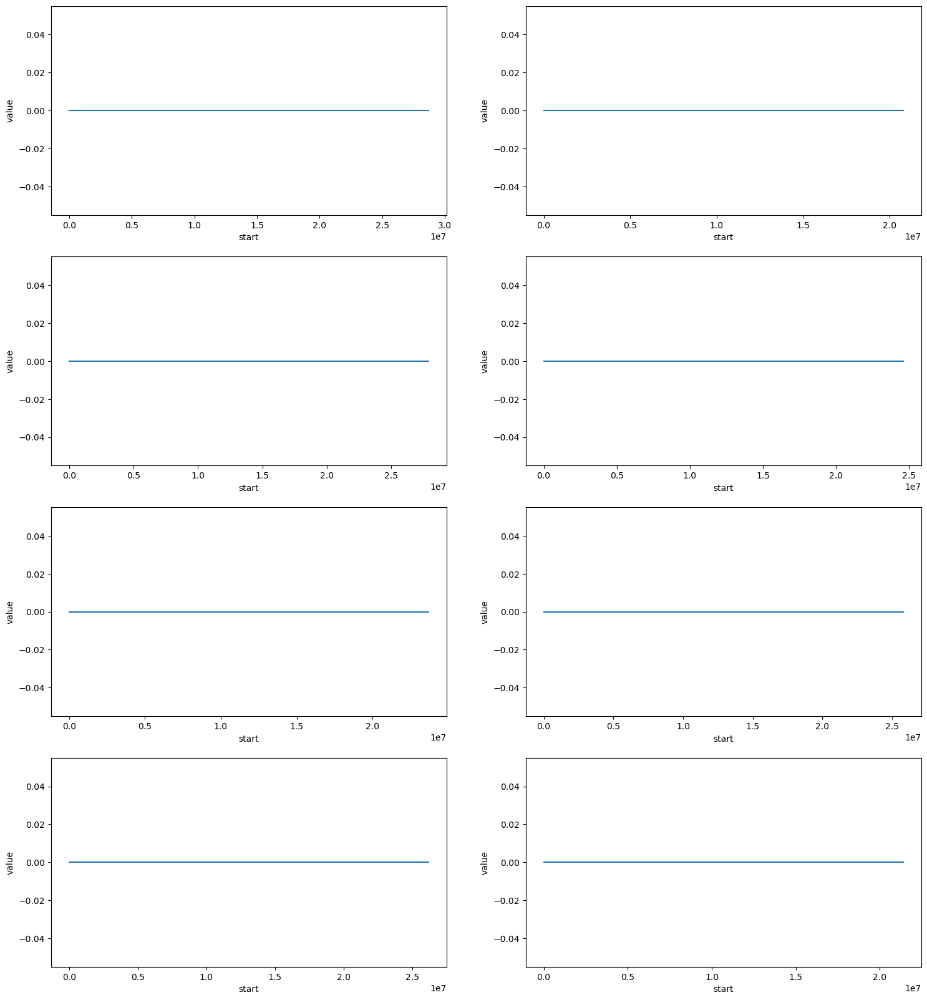

In [13]:
fig = plt.figure(figsize=(18, 20))
ax = fig.add_subplot(4,2,1)
sns.lineplot(x=pionly[pionly.Chr == "scaffold_1"].start, y=pionly[pionly.Chr == "scaffold_1"]["value"])
ax = fig.add_subplot(4,2,2)
sns.lineplot(x=pionly[pionly.Chr == "scaffold_2"].start, y=pionly[pionly.Chr == "scaffold_2"]["value"], legend=False)
ax = fig.add_subplot(4,2,3)
sns.lineplot(x=pionly[pionly.Chr == "scaffold_3"].start, y=pionly[pionly.Chr == "scaffold_3"]["value"], legend=False)
ax = fig.add_subplot(4,2,4)
sns.lineplot(x=pionly[pionly.Chr == "scaffold_4"].start, y=pionly[pionly.Chr == "scaffold_4"]["value"], legend=False)
ax = fig.add_subplot(4,2,5)
sns.lineplot(x=pionly[pionly.Chr == "scaffold_5"].start, y=pionly[pionly.Chr == "scaffold_5"]["value"], legend=False)
ax = fig.add_subplot(4,2,6)
sns.lineplot(x=pionly[pionly.Chr == "scaffold_6"].start, y=pionly[pionly.Chr == "scaffold_6"]["value"], legend=False)
ax = fig.add_subplot(4,2,7)
sns.lineplot(x=pionly[pionly.Chr == "scaffold_7"].start, y=pionly[pionly.Chr == "scaffold_7"]["value"], legend=False)
ax = fig.add_subplot(4,2,8)
sns.lineplot(x=pionly[pionly.Chr == "scaffold_8"].start, y=pionly[pionly.Chr == "scaffold_8"]["value"], legend=False)


AttributeError: 'DataFrame' object has no attribute 'Chr'

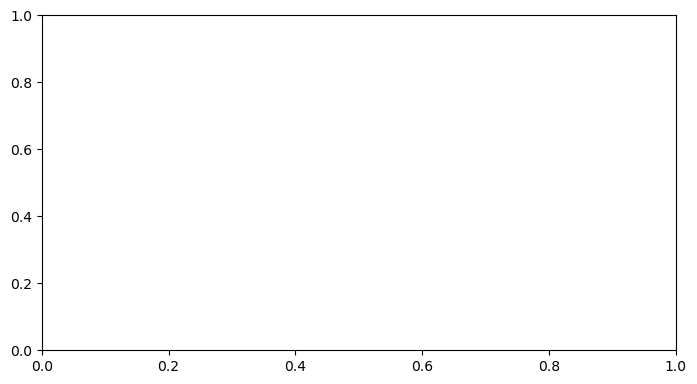

In [8]:
fig = plt.figure(figsize=(18, 20))
ax = fig.add_subplot(4,2,1)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_1"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_1"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_1"].pop1)
ax = fig.add_subplot(4,2,2)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_2"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_2"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_2"].pop1, legend=False)
ax = fig.add_subplot(4,2,3)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_3"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_3"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_3"].pop1, legend=False)
ax = fig.add_subplot(4,2,4)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_4"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_4"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_4"].pop1, legend=False)
ax = fig.add_subplot(4,2,5)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_5"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_5"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_5"].pop1, legend=False)
ax = fig.add_subplot(4,2,6)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_6"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_6"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_6"].pop1, legend=False)
ax = fig.add_subplot(4,2,7)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_7"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_7"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_7"].pop1, legend=False)
ax = fig.add_subplot(4,2,8)
sns.lineplot(x=pionly_sp[pionly_sp.Chr == "scaffold_8"].start, y=pionly_sp[pionly_sp.Chr == "scaffold_8"]["value"], hue=pionly_sp[pionly_sp.Chr == "scaffold_8"].pop1, legend=False)


In [15]:
pionly[pionly["value"] > 0]

,Chr,start,end,nSites,pop1,pop2,nUsed,metric,value,numerator,denominator,nGeno,nMiss


In [3]:
met = pd.read_csv("Metadata final file 2025-11 - Individuals.tsv", sep="\t")
met.head()

,VCF,individual code,ploidy,population,lat,lon,bioproject,biosample,SRA_code,total N read pairs,mean depth after deduplication,% of genome covered by reads,present in filtered VCF
0,arenosa,AKE01ta,4,AKE,59.441570,18.270790,PRJEB49474,SAMEA120470175,ERS27170861,119000000,47.53,84.83,present
1,arenosa,AVS01ta,4,AVS,56.899510,14.557430,PRJEB49474,SAMEA120470176,ERS27170862,200000000,76.30,85.07,present
2,arenosa,BAB01da,2,BAB,49.043514,20.180772,PRJNA592307,SAMN13420535,SRR10549990,89459597,43.47,85.95,present
3,arenosa,BAB03da,2,BAB,49.043514,20.180772,PRJNA592307,SAMN33010644,SRR23469399,91115196,35.52,85.13,present
4,arenosa,BAB04da,2,BAB,49.043514,20.180772,PRJNA592307,SAMN13420537,SRR10549988,77721200,38.45,85.80,present


In [5]:
ent = pd.read_csv("k6_ancestry_data_all.csv", sep=",")
ent.head()

,Coordinate,Individual,pop,lat,lon,K,Proportion
0,1,BDO01da,BDO,47.458,18.924778,K1,0.000271
1,2,BDO02da,BDO,47.458,18.924778,K1,0.000181
2,3,BDO03da,BDO,47.458,18.924778,K1,0.000291
3,4,BDO04da,BDO,47.458,18.924778,K1,0.000249
4,5,BDO05da,BDO,47.458,18.924778,K1,0.000201


In [11]:
ent_pivo = ent.loc[:, ["Individual", "K", "Proportion"]].pivot(columns="K", index="Individual")

In [13]:
ent_pivo.to_csv("ent_pivo.tsv", sep="\t")

In [16]:
ent_pivo = pd.read_csv("ent_pivo.tsv", sep="\t")
ent_pivo.head()

,Individual,K1,K2,K3,K4,K5,K6
0,AKE01ta,0.000441,0.029015,0.001736,0.963964,0.003211,0.001633
1,AVS01ta,0.000602,0.000352,0.000970,0.997110,0.000411,0.000555
2,BAB01da,0.007039,0.836776,0.004689,0.144541,0.002229,0.004726
3,BAB03da,0.003541,0.820839,0.003346,0.154797,0.005682,0.011795
4,BAB04da,0.011274,0.810715,0.016532,0.137195,0.002340,0.021944


In [17]:
met = met.rename(columns={"individual code":"Individual"})

In [19]:
met = met.merge(ent_pivo, on="Individual", how="outer")

In [20]:
met.to_csv("Metadata_arenosa.tsv", sep="\t", index=False)